# Paying More for Similar Drugs: Medicare Part D
**Team 6 (QST843, Fall 2026):** Linh Le (PM), Anna Wei, Zexuan Wang, Stephanie (Yu-Chien) Chen, Kefei Zhang, Alexander Shah

## Executive Summary
Medicare Part D spending is concentrated in brand-name drugs: in 2024 they made up 15% of brand and generic claims but 88% of spending, and brand spending rose from \$148.9 billion in 2022 to \$201.4 billion in 2024 while generic spending fell from \$29.9 billion to \$27.0 billion. Using CMS prescriber-level data for 2022–2024 (80.7 million prescriber-drug records) joined with HRSA shortage-area and HUD ZIP-county data in PySpark, we examined how drug costs and prescribing patterns vary by specialty, location, and patient mix. Cost per claim differs widely by specialty, from under \$85 in Family and General Practice to \$443 in Endocrinology in 2024, while the cost of a 30-day fill of the same common drug is fairly consistent across prescribers. Overall averages hide important differences: the rural–urban opioid gap and the link between low-income patients and generic use are near zero overall but substantial within specific specialties. Cost-reduction efforts should therefore focus on brand-name drugs and on specific specialty groups, especially primary care practices serving many dual-eligible patients, rather than on broad geographic averages.

## 1. Project Overview

### Business Problem Definition
When a prescriber chooses a brand-name drug over a generic alternative, Medicare Part D and beneficiaries may face higher prescription costs. As a result, understanding where these cost differences occur can reveal opportunities for more cost-effective prescribing and potential healthcare savings.

Using Medicare Part D prescription and spending data at the individual prescriber level, this project aims to understand cost variations across prescribers and regions, and identify where spending could be reduced for comparable prescribing volume. We will:

- Examine how prescriber specialty, location, urban/rural status, and local provider shortages relate to drug costs.
- Compare brand-name and generic prescribing patterns and estimate potential savings from lower-cost drug alternatives.
- Identify prescribers and regions with unusually high costs compared with similar peers.
- Identify where potential cost-reduction efforts could have the greatest impact.

### Data Sources

- **Prescriber-Drug Detail:** Centers for Medicare & Medicaid Services (CMS), U.S. Department of Health & Human Services - Medicare Part D Prescribers by Provider and Drug ([View Dataset](https://data.cms.gov/provider-summary-by-type-of-service/medicare-part-d-prescribers/medicare-part-d-prescribers-by-provider-and-drug))
- **Prescriber Summary:** CMS - Medicare Part D Prescribers by Provider. Includes prescriber ZIP code, specialty, and urban/rural classification ([View Dataset](https://data.cms.gov/provider-summary-by-type-of-service/medicare-part-d-prescribers/medicare-part-d-prescribers-by-provider))
- **Drug Spending:** CMS - Medicare Part D Spending by Drug. Includes cost per dosage unit, manufacturers, and drug information ([View Dataset](https://data.cms.gov/summary-statistics-on-use-and-payments/medicare-medicaid-spending-by-drug/medicare-part-d-spending-by-drug))
- **Health Professional Shortage Areas (HPSA):** Health Resources & Services Administration (HRSA), U.S. Department of Health & Human Services - Primary Care, Dental Health, and Mental Health HPSA designations ([View Dataset](https://data.hrsa.gov/data/download))
- **ZIP-County Crosswalk:** U.S. Department of Housing & Urban Development (HUD) - USPS ZIP-County Crosswalk. Used to link prescriber ZIP codes to counties ([View Dataset](https://www.huduser.gov/portal/datasets/usps_crosswalk.html))

**Total size:** About 85.1 million rows, 11 files, about 14.8 GB (2022–2024).

**License:** All datasets are public data published by U.S. federal agencies (CMS, HRSA, HUD); they are U.S. government works and free to use. Code is released under the MIT License.

**Access:** Public downloads are linked in the Data Sources section and References. Team copies are stored in Google Cloud Storage (project `ba843teamproject`): `gs://cms_partd_drug_detail/`, `gs://cms_partd_prescriber_summary/`, `gs://cms_partd_drug_spending/`, `gs://hrsa_shortageareas/`, `gs://hud_zip_county/`. Cleaned and joined outputs (Parquet): `gs://partd_data_outputs/clean/` and `gs://partd_data_outputs/master/master_dataset/`. Run with PySpark in JupyterLab on the team's Dataproc cluster.

> **Takeaway:** Brand-name prescribing where generics exist is a measurable cost driver, and CMS prescriber-level data lets us locate it by specialty, region, and shortage area.

## 2. Cleaning Phase

### 2.1 Loading Raw Datasets from GCS

In [ ]:
drug_detail = spark.read.csv("gs://cms_partd_drug_detail/", header=True)
prescriber = spark.read.csv("gs://cms_partd_prescriber_summary/", header=True)
spending = spark.read.csv("gs://cms_partd_drug_spending/", header=True)
hrsa = spark.read.csv("gs://hrsa_shortageareas/", header=True)
hud = spark.read.csv("gs://hud_zip_county/", header=True)

#### Inspect existing schema

In [ ]:
drug_detail.printSchema()
spending.printSchema()
prescriber.printSchema()
hrsa.printSchema()
hud.printSchema()


drug_detail.show(5, truncate=False)
spending.show(5, truncate=False)
prescriber.show(5, truncate=False)
hrsa.show(5, truncate=False)
hud.show(5, truncate=False)

root
 |-- Prscrbr_NPI: string (nullable = true)
 |-- Prscrbr_Last_Org_Name: string (nullable = true)
 |-- Prscrbr_First_Name: string (nullable = true)
 |-- Prscrbr_City: string (nullable = true)
 |-- Prscrbr_State_Abrvtn: string (nullable = true)
 |-- Prscrbr_State_FIPS: string (nullable = true)
 |-- Prscrbr_Type: string (nullable = true)
 |-- Prscrbr_Type_Src: string (nullable = true)
 |-- Brnd_Name: string (nullable = true)
 |-- Gnrc_Name: string (nullable = true)
 |-- Tot_Clms: string (nullable = true)
 |-- Tot_30day_Fills: string (nullable = true)
 |-- Tot_Day_Suply: string (nullable = true)
 |-- Tot_Drug_Cst: string (nullable = true)
 |-- Tot_Benes: string (nullable = true)
 |-- GE65_Sprsn_Flag: string (nullable = true)
 |-- GE65_Tot_Clms: string (nullable = true)
 |-- GE65_Tot_30day_Fills: string (nullable = true)
 |-- GE65_Tot_Drug_Cst: string (nullable = true)
 |-- GE65_Tot_Day_Suply: string (nullable = true)
 |-- GE65_Bene_Sprsn_Flag: string (nullable = true)
 |-- GE65_Tot_Ben

+-----------+---------------------+------------------+------------+--------------------+------------------+-----------------+----------------+--------------------+--------------------+--------+---------------+-------------+------------+---------+---------------+-------------+--------------------+-----------------+------------------+--------------------+--------------+
|Prscrbr_NPI|Prscrbr_Last_Org_Name|Prscrbr_First_Name|Prscrbr_City|Prscrbr_State_Abrvtn|Prscrbr_State_FIPS|Prscrbr_Type     |Prscrbr_Type_Src|Brnd_Name           |Gnrc_Name           |Tot_Clms|Tot_30day_Fills|Tot_Day_Suply|Tot_Drug_Cst|Tot_Benes|GE65_Sprsn_Flag|GE65_Tot_Clms|GE65_Tot_30day_Fills|GE65_Tot_Drug_Cst|GE65_Tot_Day_Suply|GE65_Bene_Sprsn_Flag|GE65_Tot_Benes|
+-----------+---------------------+------------------+------------+--------------------+------------------+-----------------+----------------+--------------------+--------------------+--------+---------------+-------------+------------+---------+------------

+-----------------------------+--------------------+--------+---------------+---------------+-----------------+-------------+--------------+-------------------------------+---------------------+----------------------+-----------------+---------------+-----------------+-------------+--------------+-------------------------------+---------------------+----------------------+-----------------+---------------+-----------------+-------------+--------------+-------------------------------+---------------------+----------------------+-----------------+---------------+-----------------+-------------+--------------+-------------------------------+---------------------+----------------------+-----------------+---------------+-----------------+-------------+--------------+-------------------------------+---------------------+----------------------+-----------------+------------------------------+-------------------------------+
|Brnd_Name                    |Gnrc_Name           |Tot_Mftr|Mftr_Nam

+-----------+---------------------+------------------+----------+---------------+--------------+---------------------------+---------------------------------------------+-------------+--------------------+------------------+------------+------------+-----------------------------------------------------------------------------------+-------------+-------------------+----------------+--------+---------------+------------+-------------+---------+---------------+-------------+--------------------+-----------------+------------------+--------------------+--------------+---------------+-------------+-----------------+---------------+-------------+-----------------+---------------+-------------+-----------------+---------------+-------------+-----------------+--------------+------------+----------------+--------------+------------+------------+-----------------+---------------+---------------+---------------+-------------------+----------------+----------------+-------------------+-----------

+---------------------------------------------+----------+---------------------------------+---------------------+----------+-------------+--------------------------+-----------+---------------------+---------------------------------+----------------------+------------------------------------+-----------------------+--------------+--------+---------------------------+----------------------------------+-----------------+--------------------------+------------+------------+-----------+-----------------------------------------+--------------------+------------------+------------------+------------------+-------------------------+-----------------------------+----------------------+-------------------+----------------------+------------------------------------------------------------------------+-----------------------+---------------------------+---------------------+---------------------------------------------+-------------------------------------------+---------------------------------

+---+-----+----------+-----+-------------------+------------------+----------------+-------------------+
|zip|geoid|city      |state|res_ratio          |bus_ratio         |oth_ratio       |tot_ratio          |
+---+-----+----------+-----+-------------------+------------------+----------------+-------------------+
|501|36103|HOLTSVILLE|NY   |0.0                |1.0               |0.0             |1.0                |
|601|72081|ADJUNTAS  |PR   |0.0025510204081633 |0.0050251256281407|0.01219512195122|0.0029493945979509 |
|601|72001|ADJUNTAS  |PR   |0.99744897959184   |0.99497487437186  |0.98780487804878|0.99705060540205   |
|602|72005|AGUADA    |PR   |0.0                |0.0010172939979654|0.0             |7.6010945576163e-05|
|602|72117|AGUADA    |PR   |0.00058641199631398|0.0               |0.0             |0.00053207661903314|
+---+-----+----------+-----+-------------------+------------------+----------------+-------------------+
only showing top 5 rows

### 2.2 Check row counts and null values

In [ ]:
from pyspark.sql.functions import col, sum, when

def check_nulls(df, name):
    total_rows = df.count()

    null_counts = df.select([
        sum(
            when(col(f"`{c}`").isNull(), 1).otherwise(0)
        ).alias(c)
        for c in df.columns
    ])

    print(f"\nNull values in {name}:")
    null_counts.show(vertical=True)

    print(f"Total rows: {total_rows}")

#### Drug Detail: Prescribers Provider and Drug

In [ ]:
check_nulls(drug_detail, "Drug Detail")

Dataset: Drug Detail
Total rows: 80,688,291
Total columns: 22
Null values:

#### Prescriber Summary: Prescribers by Provider

In [ ]:
check_nulls(prescriber, "Prescriber Summary")

Null values in Prescriber Summary:

-RECORD 0---------------------------------
 Prscrbr_NPI                    | 0       
 Prscrbr_Last_Org_Name          | 0       
 Prscrbr_First_Name             | 7       
 Prscrbr_MI                     | 1449438 
 Prscrbr_Crdntls                | 400653  
 Prscrbr_Ent_Cd                 | 0       
 Prscrbr_St1                    | 3       
 Prscrbr_St2                    | 3287781 
 Prscrbr_City                   | 0       
 Prscrbr_State_Abrvtn           | 0       
 Prscrbr_State_FIPS             | 5516    
 Prscrbr_Zip5                   | 151     
 Prscrbr_RUCA                   | 5516    
 Prscrbr_RUCA_Desc              | 5516    
 Prscrbr_Cntry                  | 0       
 Prscrbr_Type                   | 9       
 Prscrbr_Type_Src               | 0       
 Tot_Clms                       | 0       
 Tot_30day_Fills                | 0       
 Tot_Drug_Cst                   | 0       
 Tot_Day_Suply                  | 0       
 Tot_Benes                      | 432092  
 GE65_Sprsn

#### Spending by Drug

It is important to note that for this dataset, the total row count represents aggregated records by year rather than unique records across the entire reporting period. Each row should be interpreted in the context of its corresponding reporting year.

In [ ]:
check_nulls(spending, "Spending")

Null values in Spending:

-RECORD 0-------------------------------
 Brnd_Name                       | 0    
 Gnrc_Name                       | 0    
 Tot_Mftr                        | 0    
 Mftr_Name                       | 0    
 Tot_Spndng_2020                 | 4233 
 Tot_Dsg_Unts_2020               | 4233 
 Tot_Clms_2020                   | 4233 
 Tot_Benes_2020                  | 4314 
 Avg_Spnd_Per_Dsg_Unt_Wghtd_2020 | 4233 
 Avg_Spnd_Per_Clm_2020           | 4233 
 Avg_Spnd_Per_Bene_2020          | 4445 
 Outlier_Flag_2020               | 4236 
 Tot_Spndng_2021                 | 3338 
 Tot_Dsg_Unts_2021               | 3338 
 Tot_Clms_2021                   | 3338 
 Tot_Benes_2021                  | 3534 
 Avg_Spnd_Per_Dsg_Unt_Wghtd_2021 | 3338 
 Avg_Spnd_Per_Clm_2021           | 3338 
 Avg_Spnd_Per_Bene_2021          | 3601 
 Outlier_Flag_2021               | 3341 
 Tot_Spndng_2022                 | 2414 
 Tot_Dsg_Unts_2022               | 2414 
 Tot_Clms_2022                   | 2414 
 Tot_Benes_2022 

#### HRSA: Shortage Areas

In [ ]:
check_nulls(hrsa, "HRSA")

Null values in HRSA:

-RECORD 0--------------------------------------------------------------------------
 HPSA Name                                                                | 0      
 HPSA ID                                                                  | 0      
 Designation Type                                                         | 0      
 HPSA Discipline Class                                                    | 0      
 HPSA Score                                                               | 0      
 PC MCTA Score                                                            | 0      
 Primary State Abbreviation                                               | 0      
 HPSA Status                                                              | 0      
 HPSA Designation Date                                                    | 0      
 HPSA Designation Last Update Date                                        | 0      
 Metropolitan Indicator                                                   | 

#### HUD ZIP County

This file was initially downloaded as an Excel file instead of CSV, so conversion is needed in order to read properly. Once converted, the file is uploaded as a CSV to the Google Clouse Storage bucket.

In [ ]:
!gcloud storage cp gs://hud_zip_county/HUD_ZIP-COUNTY_122024.xlsx .

Copying gs://hud_zip_county/HUD_ZIP-COUNTY_122024.xlsx to file://./HUD_ZIP-COUNTY_122024.xlsx
  Completed files 1/1 | 2.3MiB/2.3MiB                                          
Average throughput: 165.4MiB/s

In [ ]:
import pandas as pd

hud_df = pd.read_excel("HUD_ZIP-COUNTY_122024.xlsx")

hud_df.to_csv("hud_zip_county.csv", index=False)

In [ ]:
!gcloud storage cp hud_zip_county.csv gs://hud_zip_county/

Copying file://hud_zip_county.csv to gs://hud_zip_county/hud_zip_county.csv
  Completed files 1/1 | 3.0MiB/3.0MiB                                          

Reloading into Spark

In [ ]:
hud_new = spark.read.csv(
    "gs://hud_zip_county/hud_zip_county.csv",
    header=True,
    inferSchema=True
)

hud_new.printSchema()
hud_new.show(5, truncate=False)

root
 |-- zip: integer (nullable = true)
 |-- geoid: integer (nullable = true)
 |-- city: string (nullable = true)
 |-- state: string (nullable = true)
 |-- res_ratio: double (nullable = true)
 |-- bus_ratio: double (nullable = true)
 |-- oth_ratio: double (nullable = true)
 |-- tot_ratio: double (nullable = true)

+---+-----+----------+-----+------------------+------------------+----------------+------------------+
|zip|geoid|city      |state|res_ratio         |bus_ratio         |oth_ratio       |tot_ratio         |
+---+-----+----------+-----+------------------+------------------+----------------+------------------+
|501|36103|HOLTSVILLE|NY   |0.0               |1.0               |0.0             |1.0               |
|601|72081|ADJUNTAS  |PR   |0.0025510204081633|0.0050251256281407|0.01219512195122|0.0029493945979509|
|601|72001|ADJUNTAS  |PR   |0.99744897959184  |0.99497487437186  |0.98780487804878|0.99705060540205  |
|602|72005|AGUADA    |PR   |0.0               |0.0010172939979654|0.0             |7.6010945576163E-5|
|602|72117|AGUADA    |PR   |5.8641199631398E-4|0.0               |0.0             |5.3207661903314E-4|
+---+-----+----------+-----+------------------+------------------+----------------+------------------+
only showing top 5 rows

Calculate total rows and null count for the new HUD ZIP County file

In [ ]:
def check_nulls(df, name):
    total_rows = df.count()
    total_columns = len(df.columns)

    null_counts = df.select([
        sum(
            when(col(f"`{c}`").isNull(), 1).otherwise(0)
        ).alias(c)
        for c in df.columns
    ])

    print(f"\nDataset: {name}")
    print(f"Total rows: {total_rows:,}")
    print(f"Total columns: {total_columns}")

    print("\nNull values:")
    null_counts.show(vertical=True)

check_nulls(hud_new, "HUD")

Dataset: HUD
Total rows: 54,553
Total columns: 8
Null values:

-RECORD 0--------
 zip       | 0   
 geoid     | 0   
 city      | 0   
 state     | 0   
 res_ratio | 0   
 bus_ratio | 0   
 oth_ratio | 0   
 tot_ratio | 0   

The initial inspection indicates that the first three datasets from CMS Medicare Part D loaded successfully. All three are CSV files, and their fields are currently being read as strings, so data type standardization will be implemented during cleaning.

In addition, the HRSA Health Professional Shortage Areas dataset loaded successfully, with the exception of an extra column (`_c65`) that appears to contain only null values. The HUD ZIP-County Crosswalk file (`HUD_ZIP-COUNTY_122024.xlsx`) was also not read correctly because it is an Excel file rather than a CSV. It will need to be converted to CSV before it can be properly loaded and standardized in Spark.

### 2.3 Standardization

#### Drug Detail: Prescribers Provider and Drug
The CMS Part D Prescribers by Provider and Drug files for 2022-2024 are stored in the `cms_partd_drug_detail` bucket with one CSV per year. Since the raw files do not include a year column, each file was read separately and a `year` column was added from its file name to distinguish between the datasets. The three years were then combined by column name, which confirms the files share the same 22 columns (23 with `year`).

In [ ]:
!gcloud storage ls gs://cms_partd_drug_detail/

gs://cms_partd_drug_detail/2022_Prescribers_Provider_and_Drug.csv
gs://cms_partd_drug_detail/2023_Prescribers_Provider_and_Drug.csv
gs://cms_partd_drug_detail/2024_Prescribers_Provider_and_Drug.csv

In [ ]:
from functools import reduce
from pyspark.sql import functions as F

base = "gs://cms_partd_drug_detail/"
frames = [
    spark.read.csv(f"{base}{y}_Prescribers_Provider_and_Drug.csv", header=True)
         .withColumn("year", F.lit(y))
    for y in (2022, 2023, 2024)
]
drug_detail = reduce(lambda a, b: a.unionByName(b), frames)
drug_detail.columns

['Prscrbr_NPI',
 'Prscrbr_Last_Org_Name',
 'Prscrbr_First_Name',
 'Prscrbr_City',
 'Prscrbr_State_Abrvtn',
 'Prscrbr_State_FIPS',
 'Prscrbr_Type',
 'Prscrbr_Type_Src',
 'Brnd_Name',
 'Gnrc_Name',
 'Tot_Clms',
 'Tot_30day_Fills',
 'Tot_Day_Suply',
 'Tot_Drug_Cst',
 'Tot_Benes',
 'GE65_Sprsn_Flag',
 'GE65_Tot_Clms',
 'GE65_Tot_30day_Fills',
 'GE65_Tot_Drug_Cst',
 'GE65_Tot_Day_Suply',
 'GE65_Bene_Sprsn_Flag',
 'GE65_Tot_Benes',
 'year']

In [ ]:
drug_detail.groupBy("year").count().show()

+----+--------+
|year|   count|
+----+--------+
|2022|25869521|
|2023|26794878|
|2024|28023892|
+----+--------+

##### Casting

In [ ]:
long_cols = ["Tot_Clms", "Tot_Day_Suply", "Tot_Benes",
             "GE65_Tot_Clms", "GE65_Tot_Day_Suply", "GE65_Tot_Benes"]
dbl_cols  = ["Tot_30day_Fills", "Tot_Drug_Cst",
             "GE65_Tot_30day_Fills", "GE65_Tot_Drug_Cst"]

for c in long_cols:
    drug_detail = drug_detail.withColumn(c, F.col(c).cast("long"))
for c in dbl_cols:
    drug_detail = drug_detail.withColumn(c, F.col(c).cast("double"))

drug_detail.printSchema()

root
 |-- Prscrbr_NPI: string (nullable = true)
 |-- Prscrbr_Last_Org_Name: string (nullable = true)
 |-- Prscrbr_First_Name: string (nullable = true)
 |-- Prscrbr_City: string (nullable = true)
 |-- Prscrbr_State_Abrvtn: string (nullable = true)
 |-- Prscrbr_State_FIPS: string (nullable = true)
 |-- Prscrbr_Type: string (nullable = true)
 |-- Prscrbr_Type_Src: string (nullable = true)
 |-- Brnd_Name: string (nullable = true)
 |-- Gnrc_Name: string (nullable = true)
 |-- Tot_Clms: long (nullable = true)
 |-- Tot_30day_Fills: double (nullable = true)
 |-- Tot_Day_Suply: long (nullable = true)
 |-- Tot_Drug_Cst: double (nullable = true)
 |-- Tot_Benes: long (nullable = true)
 |-- GE65_Sprsn_Flag: string (nullable = true)
 |-- GE65_Tot_Clms: long (nullable = true)
 |-- GE65_Tot_30day_Fills: double (nullable = true)
 |-- GE65_Tot_Drug_Cst: double (nullable = true)
 |-- GE65_Tot_Day_Suply: long (nullable = true)
 |-- GE65_Bene_Sprsn_Flag: string (nullable = true)
 |-- GE65_Tot_Benes: long (

##### Standardize Brand/Generic Flag

In [ ]:
drug_detail = drug_detail.withColumn(
    "is_generic", F.lower(F.trim("Brnd_Name")) == F.lower(F.trim("Gnrc_Name")))
drug_detail.select("Brnd_Name", "Gnrc_Name", "is_generic").show(6, truncate=False)

+--------------------+--------------------+----------+
|Brnd_Name           |Gnrc_Name           |is_generic|
+--------------------+--------------------+----------+
|Amlodipine Besylate |Amlodipine Besylate |true      |
|Atorvastatin Calcium|Atorvastatin Calcium|true      |
|Eliquis             |Apixaban            |false     |
|Escitalopram Oxalate|Escitalopram Oxalate|true      |
|Hydrochlorothiazide |Hydrochlorothiazide |true      |
|Levofloxacin        |Levofloxacin        |true      |
+--------------------+--------------------+----------+
only showing top 6 rows

#### Prescriber Summary: Prescribers by Provider
The CMS Part D Prescribers by Provider files for 2022-2024 are stored in the `cms_partd_prescriber_summary` bucket with one CSV per year. The raw files are do not include a year column, each file was read separately and a `year` column was added from its file name to distinguish between the datasets. The three years were then combined by column name, which confirms the files share the same 84 columns (85 with `year`).

In [ ]:
!gcloud storage ls gs://cms_partd_prescriber_summary/

gs://cms_partd_prescriber_summary/2022_Prescribers_by_Provider.csv
gs://cms_partd_prescriber_summary/2023_Prescribers_by_Provider.csv
gs://cms_partd_prescriber_summary/2024_Prescribers_by_Provider.csv

In [ ]:
base = "gs://cms_partd_prescriber_summary/"
frames = [
    spark.read.csv(f"{base}{y}_Prescribers_by_Provider.csv", header=True)
         .withColumn("year", F.lit(y))
    for y in (2022, 2023, 2024)
]
prescriber = reduce(lambda a, b: a.unionByName(b), frames)
len(prescriber.columns), prescriber.columns[-3:]

(85, ['Bene_Ndual_Cnt', 'Bene_Avg_Risk_Scre', 'year'])

Next, ZIP code lengths were checked to prepare the field for use as a join key with HUD data. One issue identified was that some CMS prescriber ZIP codes were missing leading zeros, leaving certain ZIP codes with only four digits. After reviewing this further, these were confirmed to be valid ZIP code formats rather than data errors, as four-digit ZIP codes are common in states such as MA, NJ, CT, ME, NH, RI, and VT. To make the ZIP codes consistent with HUD data, the `zip5_clean` field pads valid 3–5 digit ZIP codes to five digits. Placeholder or invalid values, including `0`, one- or two-digit ZIP codes, and nulls, were set to null. As a result, 181 rows will not be matched to a county.

In [ ]:
prescriber.groupBy(F.length("Prscrbr_Zip5").alias("zip_len")).count().show()

+-------+-------+
|zip_len|  count|
+-------+-------+
|   NULL|    151|
|      1|     22|
|      3|  34425|
|      4| 355764|
|      5|3739487|
|      2|      8|
+-------+-------+

In [ ]:
prescriber.filter(F.length("Prscrbr_Zip5") <= 2).select("Prscrbr_NPI", "Prscrbr_City", "Prscrbr_State_Abrvtn", "Prscrbr_Zip5", "Prscrbr_Cntry").show(10, truncate=False)

prescriber.filter(F.length("Prscrbr_Zip5") == 4).groupBy("Prscrbr_State_Abrvtn").count().orderBy(F.desc("count")).show(8)

+-----------+------------+--------------------+------------+-------------+
|Prscrbr_NPI|Prscrbr_City|Prscrbr_State_Abrvtn|Prscrbr_Zip5|Prscrbr_Cntry|
+-----------+------------+--------------------+------------+-------------+
|1790965598 |London      |ZZ                  |0           |CA           |
|1548840085 |San Fernando|ZZ                  |0           |TT           |
|1366672248 |Guaynabo    |PR                  |96          |US           |
|1114060506 |Fall River  |MA                  |0           |US           |
|1457431231 |Arecibo     |PR                  |61          |US           |
|1326643552 |Rio Grande  |PR                  |74          |US           |
|1962945014 |Beirut      |ZZ                  |0           |LB           |
|1366672248 |Guaynabo    |PR                  |96          |US           |
|1770699324 |Apo         |AE                  |0           |US           |
|1790481760 |London      |GU                  |0           |US           |
+-----------+------------

+--------------------+------+
|Prscrbr_State_Abrvtn| count|
+--------------------+------+
|                  MA|119352|
|                  NJ|108539|
|                  CT| 58620|
|                  ME| 21425|
|                  NH| 21261|
|                  RI| 17288|
|                  VT|  8762|
|                  AE|   345|
+--------------------+------+
only showing top 8 rows

Padding ZIP codes to maintain a consistent five-digit format.

In [ ]:
prescriber = prescriber.withColumn(
    "zip5_clean",
    F.when(F.length("Prscrbr_Zip5").between(3, 5), F.lpad("Prscrbr_Zip5", 5, "0"))
)
prescriber.groupBy(F.length("zip5_clean").alias("len")).count().show()

+----+-------+
| len|  count|
+----+-------+
|NULL|    181|
|   5|4129676|
+----+-------+

##### Casting

In [ ]:
text_cols = [c for c in prescriber.columns
             if c.startswith("Prscrbr_") or c.endswith("_Flag") or c in ("zip5_clean", "year")]
num_cols = [c for c in prescriber.columns if c not in text_cols]

for c in num_cols:
    prescriber = prescriber.withColumn(c, F.col(c).cast("double"))

from collections import Counter
len(num_cols), Counter(t for _, t in prescriber.dtypes)

(56, Counter({'double': 56, 'string': 29, 'int': 1}))

#### Spending Drug

In [ ]:
!gcloud storage ls gs://cms_partd_drug_spending/

gs://cms_partd_drug_spending/PartD_Spending_by_Drug.csv

In [ ]:
spending = spark.read.csv("gs://cms_partd_drug_spending/PartD_Spending_by_Drug.csv", header=True)
len(spending.columns), spending.count()

(46, 14536)

##### Casting

In [ ]:
text_cols = ["Brnd_Name", "Gnrc_Name", "Mftr_Name"] + [c for c in spending.columns if c.startswith("Outlier_Flag_")]
num_cols = [c for c in spending.columns if c not in text_cols + ["Tot_Mftr"]]

bad = spending.agg(*[
    F.sum(F.when(F.col(c).isNotNull() & F.col(c).cast("double").isNull(), 1).otherwise(0)).alias(c)
    for c in num_cols
]).collect()[0].asDict()
print("failed casts:", {c: n for c, n in bad.items() if n})

spending = spending.withColumn("Tot_Mftr", F.col("Tot_Mftr").cast("int"))
for c in num_cols:
    spending = spending.withColumn(c, F.col(c).cast("double"))

from collections import Counter
Counter(t for _, t in spending.dtypes)

failed casts: {}

Counter({'double': 37, 'string': 8, 'int': 1})

#### HRSA Shortage Areas

In [ ]:
!gcloud storage ls gs://hrsa_shortageareas/

gs://hrsa_shortageareas/HRSA_ShortageArea_DH.csv
gs://hrsa_shortageareas/HRSA_ShortageArea_MH.csv
gs://hrsa_shortageareas/HRSA_ShortageArea_PC.csv

Examine columns and file layout

In [ ]:
base = "gs://hrsa_shortageareas/"
hrsa_frames = {
    k: spark.read.csv(f"{base}HRSA_ShortageArea_{k}.csv", header=True)
            .withColumn("source_file", F.lit(f"HRSA_ShortageArea_{k}.csv"))
    for k in ("DH", "MH", "PC")
}

for k, d in hrsa_frames.items():
    print(k, len(d.columns), [c for c in d.columns if c.startswith("_c")])

DH 66 ['_c64']
MH 66 ['_c64']
PC 67 ['_c65']

In [ ]:
base = "gs://hrsa_shortageareas/"
parts = []
for k in ("DH", "MH", "PC"):
    d = (spark.read.option("escape", '"').csv(f"{base}HRSA_ShortageArea_{k}.csv", header=True)
              .withColumn("source_file", F.lit(f"HRSA_ShortageArea_{k}.csv")))
    stray = [c for c in d.columns if c.startswith("_c")]
    print(k, stray, [d.filter(F.col(c).isNotNull()).count() for c in stray])
    parts.append(d.drop(*stray))

hrsa = reduce(lambda a, b: a.unionByName(b, allowMissingColumns=True), parts)
len(hrsa.columns), hrsa.count()

DH ['_c64'] [0]

MH ['_c64'] [0]

PC ['_c65'] [0]

(66, 169950)

The three HRSA shortage area files (DH, MH, PC) were read separately. Six rows had quotation marks inside organization names that split into extra fields, so the files were read with a quote-escape option to parse them correctly. The empty trailing column in each file was then dropped, and the files were combined by column name (66 columns, 169,950 rows).

In [ ]:
hrsa.groupBy("HPSA Status").count().show(truncate=False)

+-----------------------+-----+
|HPSA Status            |count|
+-----------------------+-----+
|Proposed For Withdrawal|25492|
|Withdrawn              |90755|
|Designated             |53703|
+-----------------------+-----+

The three counts add up to 169,950 so no rows are missing.

##### Casting

In [ ]:
for c in ["HPSA Score", "HPSA Shortage", "HPSA Designation Population"]:
    hrsa = hrsa.withColumn(c, F.col(f"`{c}`").cast("double"))

[(c, t) for c, t in hrsa.dtypes if c in ("HPSA Score", "HPSA Shortage", "HPSA Designation Population")]

[('HPSA Score', 'double'),
 ('HPSA Designation Population', 'double'),
 ('HPSA Shortage', 'double')]

#### HUD Zip County

In [ ]:
!gcloud storage ls gs://hud_zip_county/

gs://hud_zip_county/HUD_ZIP-COUNTY_122024.xlsx
gs://hud_zip_county/hud_zip_county.csv

In [ ]:
from pyspark.sql.types import StructType, StructField, StringType, DoubleType

hud_schema = StructType([
    StructField("zip", StringType()), StructField("geoid", StringType()),
    StructField("city", StringType()), StructField("state", StringType()),
    StructField("res_ratio", DoubleType()), StructField("bus_ratio", DoubleType()),
    StructField("oth_ratio", DoubleType()), StructField("tot_ratio", DoubleType()),
])
hud = (spark.read.csv("gs://hud_zip_county/hud_zip_county.csv", header=True, schema=hud_schema)
            .withColumn("zip", F.lpad("zip", 5, "0"))
            .withColumn("geoid", F.lpad("geoid", 5, "0")))

print(hud.count())
hud.groupBy(F.length("zip").alias("zip_len")).count().show()
hud.groupBy(F.length("geoid").alias("geoid_len")).count().show()

54553

+-------+-----+
|zip_len|count|
+-------+-----+
|      5|54553|
+-------+-----+

+---------+-----+
|geoid_len|count|
+---------+-----+
|        5|54553|
+---------+-----+

The output above confirms that every ZIP and county code is exactly 5 characters, and the 54,553 rows matches the total count earlier.

In [ ]:
import re
def snake(n): return re.sub(r"[^0-9a-zA-Z]+", "_", n.replace("%", "pct")).strip("_").lower()

hrsa = hrsa.toDF(*[snake(c) for c in hrsa.columns])
hrsa.columns[:6], len(set(hrsa.columns)) == len(hrsa.columns)

(['hpsa_name',
  'hpsa_id',
  'designation_type',
  'hpsa_discipline_class',
  'hpsa_score',
  'primary_state_abbreviation'],
 True)

## 3. Post-Cleaning Data Quality Validation
This section validates the cleaned Parquet datasets before joining them. We check missing values, failed type conversions, duplicate keys, and consistency between Drug Detail and Prescriber Summary.
All validation is performed on the cleaned datasets rather than rerunning the expensive raw-data checks in Section 2.2.

In [ ]:
!gcloud storage ls -r gs://partd_data_outputs/clean/

gs://partd_data_outputs/clean/
gs://partd_data_outputs/clean/:
gs://partd_data_outputs/clean/
gs://partd_data_outputs/clean/drug_detail/:
gs://partd_data_outputs/clean/drug_detail/
gs://partd_data_outputs/clean/drug_detail/_SUCCESS
gs://partd_data_outputs/clean/drug_detail/year=2022/:
gs://partd_data_outputs/clean/drug_detail/year=2022/
gs://partd_data_outputs/clean/drug_detail/year=2022/part-00000-7de301c0-1e1b-4765-b5b3-41c54c176206.c000.snappy.parquet
gs://partd_data_outputs/clean/drug_detail/year=2022/part-00001-7de301c0-1e1b-4765-b5b3-41c54c176206.c000.snappy.parquet
gs://partd_data_outputs/clean/drug_detail/year=2022/part-00002-7de301c0-1e1b-4765-b5b3-41c54c176206.c000.snappy.parquet
gs://partd_data_outputs/clean/drug_detail/year=2022/part-00003-7de301c0-1e1b-4765-b5b3-41c54c176206.c000.snappy.parquet
gs://partd_data_outputs/clean/drug_detail/year=2022/part-00004-7de301c0-1e1b-4765-b5b3-41c54c176206.c000.snappy.parquet
gs://partd_data_outputs/clean/drug_detail/year=2022/part-0000

In [ ]:
base_path = "gs://partd_data_outputs/clean"

drug_detail = spark.read.parquet(base_path + "/drug_detail/")
prescriber = spark.read.parquet(base_path + "/prescriber/")
hrsa = spark.read.parquet(base_path + "/hrsa/")
hud = spark.read.parquet(base_path + "/hud_zip_county/")
spending = spark.read.parquet(base_path + "/spending/")



#### Step 1 Data Quality Checks
First, check the missing values of the key fields in Drug Detail and Prescriber Summary

In [ ]:
from pyspark.sql import functions as F


detail_cols = [
    "Prscrbr_NPI", "year", "Brnd_Name",
    "Gnrc_Name", "Tot_Clms", "Tot_Drug_Cst"
]

summary_cols = [
    "Prscrbr_NPI", "year", "Prscrbr_Zip5",
    "Tot_Clms", "Tot_Drug_Cst"
]

print("Drug Detail Null Counts")
drug_detail.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in detail_cols
]).show()

print("Prescriber Summary Null Counts")
prescriber.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in summary_cols
]).show()

Drug Detail Null Counts

+-----------+----+---------+---------+--------+------------+
|Prscrbr_NPI|year|Brnd_Name|Gnrc_Name|Tot_Clms|Tot_Drug_Cst|
+-----------+----+---------+---------+--------+------------+
|          0|   0|        0|        0|       0|           0|
+-----------+----+---------+---------+--------+------------+
Prescriber Summary Null Counts

+-----------+----+------------+--------+------------+
|Prscrbr_NPI|year|Prscrbr_Zip5|Tot_Clms|Tot_Drug_Cst|
+-----------+----+------------+--------+------------+
|          0|   0|         151|       0|           0|
+-----------+----+------------+--------+------------+

The key fields in Drug Detail have no missing values.
In Prescriber Summary, 151 records have missing Prscrbr_Zip5 values, while the other checked key fields have no missing values.
These records will be retained for now and considered when evaluating ZIP-to-county matching coverage during the HUD join.

#### Step 2 Failed-Cast Checks
Check whether these two fields contain non-empty content that cannot be converted to a numeric value.

In [ ]:
from pyspark.sql import functions as F

numeric_cols = ["Tot_Clms", "Tot_Drug_Cst"]

for c in numeric_cols:
    invalid_count = prescriber.filter(
        F.col(c).isNotNull() &
        F.col(c).cast("double").isNull()
    ).count()

    print(c, "failed casts:", invalid_count)

Tot_Clms failed casts: 0

Tot_Drug_Cst failed casts: 0

No invalid numeric values were found in the Tot_Clms and Tot_Drug_Cst columns of the cleaned Prescriber Summary dataset.
Both columns can be converted to numeric types without detected casting failures among non-null values.
These results validate the current cleaned values but do not independently verify all conversions from the original raw data.

#### Step 3 Duplicate Keys Checks

In [ ]:
from pyspark.sql import functions as F

print("Drug Detail Duplicate Keys")

detail_duplicates = drug_detail.groupBy(
    "Prscrbr_NPI",
    "year",
    "Brnd_Name",
    "Gnrc_Name"
).count().filter(F.col("count") > 1)

detail_duplicates.show(10)

print("=== Prescriber Summary Duplicate Keys ===")

summary_duplicates = prescriber.groupBy(
    "Prscrbr_NPI",
    "year"
).count().filter(F.col("count") > 1)

summary_duplicates.show(10)

Drug Detail Duplicate Keys

+-----------+----+---------+---------+-----+
|Prscrbr_NPI|year|Brnd_Name|Gnrc_Name|count|
+-----------+----+---------+---------+-----+
+-----------+----+---------+---------+-----+
=== Prescriber Summary Duplicate Keys ===

+-----------+----+-----+
|Prscrbr_NPI|year|count|
+-----------+----+-----+
+-----------+----+-----+

No duplicate keys were found in either dataset using the selected key combinations.

This suggests that the cleaned datasets are unique at their expected levels of aggregation and helps reduce the risk of unintended row duplication during subsequent joins.

#### Step 4 is_generic Spot Check
Check the Brand drugs with the highest prescription volume to see if there is a problem with the is_generic classification.


In [ ]:
from pyspark.sql import functions as F

brand_check = drug_detail.filter(
    F.col("is_generic") == False
).groupBy(
    "Brnd_Name",
    "Gnrc_Name"
).agg(
    F.sum("Tot_Clms").alias("Total_Claims")
).orderBy(
    F.desc("Total_Claims")
)

brand_check.show(20, truncate=False)

+------------------------------+------------------------------+------------+
|Brnd_Name                     |Gnrc_Name                     |Total_Claims|
+------------------------------+------------------------------+------------+
|Eliquis                       |Apixaban                      |61153491    |
|Hydrocodone-Acetaminophen     |Hydrocodone/Acetaminophen     |57651734    |
|Albuterol Sulfate Hfa         |Albuterol Sulfate             |47117563    |
|Clopidogrel                   |Clopidogrel Bisulfate         |36801823    |
|Metformin Hcl Er              |Metformin Hcl                 |25958548    |
|Oxycodone-Acetaminophen       |Oxycodone Hcl/Acetaminophen   |23693964    |
|Jardiance                     |Empagliflozin                 |23142633    |
|Ozempic                       |Semaglutide                   |19323384    |
|Citalopram Hbr                |Citalopram Hydrobromide       |18797829    |
|Xarelto                       |Rivaroxaban                   |17553834    |

**Generic vs. Brand Classification — Spot Check Results**

We reviewed the top 20 highest-claim drug name combinations classified as non-generic (is_generic = False) across 2022–2024.

The results include recognizable brand-name drugs such as Eliquis, Jardiance, and Ozempic. However, several high-claim combinations show naming differences that may lead to misclassification, including:

Hydrocodone-Acetaminophen vs. Hydrocodone/Acetaminophen

Clopidogrel vs. Clopidogrel Bisulfate

Citalopram Hbr vs. Citalopram Hydrobromide

These findings suggest that exact name matching may not reliably distinguish brand and generic drugs. Further validation or an improved classification rule is recommended before using is_generic for analysis.

#### Step 5 Reconciliation Check
Check whether the total number of Drug Detail prescriptions of the same doctor in the same year exceeds the total number of prescriptions in the Prescriber Summary.

In [ ]:
from pyspark.sql import functions as F

detail_totals = drug_detail.groupBy(
    "Prscrbr_NPI", "year"
).agg(
    F.sum("Tot_Clms").alias("Detail_Claims")
)

summary_totals = prescriber.select(
    "Prscrbr_NPI",
    "year",
    F.col("Tot_Clms").cast("long").alias("Summary_Claims")
)

reconciliation = detail_totals.join(
    summary_totals,
    on=["Prscrbr_NPI", "year"],
    how="left"
)

mismatches = reconciliation.filter(
    F.col("Summary_Claims").isNotNull() &
    (F.col("Detail_Claims") > F.col("Summary_Claims"))
)

print("Reconciliation Mismatches")
mismatches.show(20)

Reconciliation Mismatches

+-----------+----+-------------+--------------+
|Prscrbr_NPI|year|Detail_Claims|Summary_Claims|
+-----------+----+-------------+--------------+
+-----------+----+-------------+--------------+

In [ ]:

unmatched = reconciliation.filter(
    F.col("Summary_Claims").isNull()
)

print("Unmatched NPI-year combinations:", unmatched.count())

unmatched.show(10)

Unmatched NPI-year combinations: 0

+-----------+----+-------------+--------------+
|Prscrbr_NPI|year|Detail_Claims|Summary_Claims|
+-----------+----+-------------+--------------+
+-----------+----+-------------+--------------+

The reconciliation check found no cases where aggregated Drug Detail claims exceeded the corresponding Prescriber Summary claims.
Additionally, all Drug Detail NPI-year combinations successfully matched to Prescriber Summary, with zero unmatched combinations.
These results support consistency between the two datasets and confirm that the NPI-year keys are suitable for the next stage of joining.

## 4. Join Preparation
In HUD data, one ZIP may correspond to multiple counties. To prevent duplicate records from being generated in subsequent joins, we need to select a County for each ZIP.


#### Step 1 HUD: one county per ZIP

In [ ]:

from pyspark.sql import functions as F
from pyspark.sql.window import Window

zip_window = Window.partitionBy("zip").orderBy(
    F.col("res_ratio").desc_nulls_last(),
    F.col("tot_ratio").desc_nulls_last(),
    F.col("geoid").asc()
)

hud_primary = (
    hud
    .withColumn("row_num", F.row_number().over(zip_window))
    .filter(F.col("row_num") == 1)
    .select(
        "zip",
        F.col("geoid").alias("county_fips"),
        "res_ratio",
        "tot_ratio"
    )
)

hud_primary.show(15, truncate=False)

+-----+-----------+----------------+----------------+
|zip  |county_fips|res_ratio       |tot_ratio       |
+-----+-----------+----------------+----------------+
|00501|36103      |0.0             |1.0             |
|00601|72001      |0.99744897959184|0.99705060540205|
|00602|72003      |0.99941358800369|0.99939191243539|
|00603|72005      |0.99934895833333|0.99935496675598|
|00604|72005      |1.0             |1.0             |
|00605|72005      |1.0             |1.0             |
|00606|72093      |1.0             |1.0             |
|00610|72011      |1.0             |1.0             |
|00611|72141      |1.0             |1.0             |
|00612|72013      |0.98947988554115|0.99065316568377|
|00613|72013      |1.0             |1.0             |
|00614|72013      |1.0             |1.0             |
|00616|72013      |1.0             |1.0             |
|00617|72017      |0.95604996808608|0.95668453748617|
|00622|72023      |1.0             |1.0             |
+-----+-----------+---------

In [ ]:

hud_duplicates = (
    hud_primary
    .groupBy("zip")
    .count()
    .filter(F.col("count") > 1)
)

print("Duplicate ZIPs:", hud_duplicates.count())

Duplicate ZIPs: 0

ZIP and county FIPS codes were retained as strings to preserve leading zeros.
The resulting hud_primary dataset will be used to map prescribers' ZIP codes to counties.

#### Step 2 HRSA Preparation


In [ ]:
from pyspark.sql import functions as F

hrsa_designated = hrsa.filter(
    F.trim(F.col("hpsa_status")) == "Designated"
)

hrsa_designated.select(
    F.count("*").alias("designated_records"),
    F.sum(
        F.col("common_state_county_fips_code").isNull().cast("int")
    ).alias("missing_county_fips"),
    F.countDistinct(
        "common_state_county_fips_code"
    ).alias("unique_counties")
).show()

+------------------+-------------------+---------------+
|designated_records|missing_county_fips|unique_counties|
+------------------+-------------------+---------------+
|             53703|                  0|           3231|
+------------------+-------------------+---------------+

In [ ]:
from pyspark.sql import functions as F

hrsa_county = (
    hrsa_designated
    .groupBy(
        F.col("common_state_county_fips_code").alias("county_fips")
    )
    .agg(
        F.countDistinct("hpsa_id").alias("hpsa_count"),
        F.max("hpsa_score").alias("max_hpsa_score"),
        F.avg("hpsa_score").alias("avg_hpsa_score")
    )
)

hrsa_county.show(15, truncate=False)

+-----------+----------+--------------+------------------+
|county_fips|hpsa_count|max_hpsa_score|avg_hpsa_score    |
+-----------+----------+--------------+------------------+
|36067      |12        |23.0          |17.397058823529413|
|51063      |6         |17.0          |15.166666666666666|
|05107      |3         |19.0          |16.333333333333332|
|31067      |7         |16.0          |12.428571428571429|
|40079      |9         |19.0          |17.77777777777778 |
|16027      |9         |25.0          |17.444444444444443|
|39149      |1         |16.0          |16.0              |
|40099      |6         |18.0          |16.0              |
|12067      |9         |21.0          |15.333333333333334|
|08085      |8         |20.0          |14.789473684210526|
|72153      |2         |24.0          |22.5              |
|13027      |2         |17.0          |15.5              |
|37089      |5         |23.0          |13.16             |
|17099      |21        |21.0          |14.76190476190476

In [ ]:

hrsa_duplicates = (
    hrsa_county
    .groupBy("county_fips")
    .count()
    .filter(F.col("count") > 1)
)

print("Duplicate counties:", hrsa_duplicates.count())
print("Total counties:", hrsa_county.count())

Duplicate counties: 0

Total counties: 3231

After filtering for Designated HPSA records, 53,703 records remained, covering 3,231 unique county FIPS codes. No missing county FIPS values were found. We aggregated the designated HPSA records to the county level using the number of distinct HPSA IDs, maximum HPSA score, and average HPSA score.

This aggregation creates one row per county and prevents one-to-many duplication during the county-level join.The HPSA metrics represent information from the 2026 extract and should not be interpreted as historical measures for each Medicare Part D year.

#### Step 3 Spending Preparation
There may be multiple manufacturer records for the same Drug at the same time, if the drug name is joined directly, the records of Drug Detail may be duplicated.

In [ ]:
from pyspark.sql import functions as F

spending_overall = spending.filter(
    F.lower(F.trim(F.col("Mftr_Name"))) == "overall"
)

spending_duplicates = (
    spending_overall
    .groupBy("Brnd_Name", "Gnrc_Name")
    .count()
    .filter(F.col("count") > 1)
)

print("Overall records:", spending_overall.count())
print("Duplicate drug combinations:", spending_duplicates.count())

spending_duplicates.show(10, truncate=False)

Overall records: 3625

Duplicate drug combinations: 0

+---------+---------+-----+
|Brnd_Name|Gnrc_Name|count|
+---------+---------+-----+
+---------+---------+-----+

The Medicare Part D Spending dataset contains both manufacturer-specific records and Overall summary records.
We selected records where Mftr_Name = "Overall" to avoid duplicating drug-level information when joining with Drug Detail.
The filtered dataset contains 3,625 records, with zero duplicate combinations of Brnd_Name and Gnrc_Name.

When joining with Drug Detail, the spending measures will be aligned with the corresponding Medicare Part D year.

## 5. Data Joins

#### Join 1 Drug Detail + Prescriber Summary
We joined Drug Detail with Prescriber Summary using Prscrbr_NPI and year as the matching keys.
A left join was used to preserve all Drug Detail records.

The joined dataset includes prescriber-level ZIP codes, total claims, total drug costs, and RUCA information.

In [ ]:
from pyspark.sql import functions as F

prescriber_selected = prescriber.select(
    "Prscrbr_NPI",
    "year",
    "zip5_clean",
    F.col("Tot_Clms").cast("long").alias("prescriber_total_claims"),
    F.col("Tot_Drug_Cst").cast("double").alias("prescriber_total_cost"),
    F.col("Prscrbr_RUCA").alias("prescriber_ruca")
)

master_step1 = drug_detail.join(
    prescriber_selected,
    on=["Prscrbr_NPI", "year"],
    how="left"
)


In [ ]:
print("Drug Detail rows:", drug_detail.count())
print("After Join 1 rows:", master_step1.count())

Drug Detail rows: 80688291

After Join 1 rows: 80688291

#### Join 2 HUD ZIP-to-County

In [ ]:
from pyspark.sql import functions as F

master_step2 = master_step1.join(
    hud_primary.select("zip", "county_fips"),
    master_step1["zip5_clean"] == hud_primary["zip"],
    how="left"
).drop("zip")


In [ ]:
master_step2.agg(
    F.count("*").alias("rows_after_join2"),
    F.sum(
        F.col("county_fips").isNull().cast("long")
    ).alias("unmatched_county_rows")
).show()

+----------------+---------------------+
|rows_after_join2|unmatched_county_rows|
+----------------+---------------------+
|        80688291|                45061|
+----------------+---------------------+

We joined the master dataset with the prepared HUD mapping using the prescriber's cleaned ZIP code (zip5_clean).

A total of 45,061 records could not be matched to a county, resulting in a county matching rate of approximately 99.94%. Unmatched records were retained with missing county FIPS values rather than being removed or assigned an arbitrary county.

#### Join 3 HRSA County-Level Metrics
The HRSA measures come from a 2026 extract and are not historical measures specific to the 2022–2024 Medicare Part D years.

In [ ]:

master_step3 = master_step2.join(
    hrsa_county,
    on="county_fips",
    how="left"
)


In [ ]:
from pyspark.sql import functions as F

master_step3.agg(
    F.count("*").alias("rows_after_join3"),
    F.sum(
        F.col("hpsa_count").isNull().cast("long")
    ).alias("unmatched_hrsa_rows")
).show()

+----------------+-------------------+
|rows_after_join3|unmatched_hrsa_rows|
+----------------+-------------------+
|        80688291|            2333082|
+----------------+-------------------+

We joined the master dataset with the county-level HRSA data using county_fips.

A total of 2,333,082 records did not match the filtered HRSA dataset.Unmatched HRSA values were retained as null. These records should not automatically be interpreted as counties without healthcare shortages.

#### Join 4 Drug Detail + Spending
Unlike the other datasets, Spending contains annual spending and claim measures in separate columns for each year. To ensure accurate matching with Drug Detail (2022–2024), we first transform the Spending data from wide format to long format.

Before performing the join, we also check the total number of records and verify that each drug-year combination is unique. This helps prevent duplicate records and ensures that spending information is aligned with the correct year.


In [ ]:
from pyspark.sql import functions as F

spending_yearly = None

for y in [2022, 2023, 2024]:

    year_data = spending_overall.select(
        "Brnd_Name",
        "Gnrc_Name",
        F.lit(y).alias("year"),
        F.col(f"Tot_Spndng_{y}").alias("spending_total"),
        F.col(f"Tot_Clms_{y}").alias("spending_claims"),
        F.col(f"Avg_Spnd_Per_Clm_{y}").alias("spending_per_claim")
    )

    if spending_yearly is None:
        spending_yearly = year_data
    else:
        spending_yearly = spending_yearly.unionByName(year_data)


In [ ]:
spending_yearly_duplicates = (
    spending_yearly
    .groupBy("Brnd_Name", "Gnrc_Name", "year")
    .count()
    .filter(F.col("count") > 1)
)

print("Spending yearly rows:", spending_yearly.count())
print("Duplicate drug-year keys:", spending_yearly_duplicates.count())

Spending yearly rows: 10875

Duplicate drug-year keys: 0

No duplicate combinations of Brnd_Name, Gnrc_Name, and year were found. This confirms that the prepared Spending dataset can be joined without introducing duplicate rows from multiple matches.

In [ ]:

master_final = master_step3.join(
    spending_yearly,
    on=["Brnd_Name", "Gnrc_Name", "year"],
    how="left"
)

In [ ]:
from pyspark.sql import functions as F

master_final.agg(
    F.count("*").alias("final_rows"),
    F.sum(
        F.col("spending_total").isNull().cast("long")
    ).alias("unmatched_spending_rows")
).show()

+----------+-----------------------+
|final_rows|unmatched_spending_rows|
+----------+-----------------------+
|  80688291|               34885005|
+----------+-----------------------+

We joined the master dataset with the year-specific Spending data using Brnd_Name, Gnrc_Name, and year.

The missing values may reflect differences in drug name matching, data coverage, or unavailable annual spending measures. These records were retained rather than removed or filled with zero.
Spending measures represent national drug-level annual aggregates and should not be summed across individual prescriber rows.

In order to make the verification more accurate, the following validations have been added to analyze the destination of unmatched data.

In [ ]:
from pyspark.sql import functions as F

spending_with_marker = spending_yearly.withColumn(
    "spending_matched", F.lit(1)
)

master_final = master_step3.join(
    spending_with_marker,
    on=["Brnd_Name", "Gnrc_Name", "year"],
    how="left"
)

master_final.agg(
    F.count("*").alias("final_rows"),
    F.sum(
        F.col("spending_matched").isNull().cast("long")
    ).alias("unmatched_drug_year_rows"),
    F.sum(
        (
            F.col("spending_matched").isNotNull() &
            F.col("spending_total").isNull()
        ).cast("long")
    ).alias("matched_but_missing_spending")
).show()

+----------+------------------------+----------------------------+
|final_rows|unmatched_drug_year_rows|matched_but_missing_spending|
+----------+------------------------+----------------------------+
|  80688291|                34882959|                        2046|
+----------+------------------------+----------------------------+

## Save the Master Dataset to Google Cloud Storage

In [ ]:
master_path = "gs://partd_data_outputs/master/master_dataset"

(
    master_final
    .write
    .mode("ignore")  # skip if already written, so Restart & Run All does not fail
    .partitionBy("year")
    .parquet(master_path)
)


In [ ]:

master_saved = spark.read.parquet(master_path)

print("Saved master rows:", master_saved.count())
print("Saved master columns:", len(master_saved.columns))

Saved master rows: 80688291

Saved master columns: 36

Load the saved master dataset for the exploratory analysis below.

In [ ]:
master = spark.read.parquet("gs://partd_data_outputs/master/master_dataset")

> **Takeaway (cleaning and joins):** All five sources were standardized, combined across 2022–2024, and joined into a master dataset of 80,688,291 rows × 36 columns. CMS-suppressed values were kept as NULL rather than zero, 99.94% of records matched a county, and unmatched HRSA and spending records were retained as missing rather than dropped.

## 6. Exploratory Questions
1. How does cost per claim vary by prescriber specialty, 2022–2024?
2. How do brand-name and generic drug prescribing patterns differ in cost and utilization, 2022–2024?
3. How does drug cost per 30-day fill vary across prescribers for the same drug in the same year?
4. How do opioid prescribing rates differ between rural and urban prescribers across specialties in 2024?
5. Do prescribers serving more low-income (dual-eligible) patients prescribe generics at a different rate?

### Q1. How does cost per claim vary by prescriber specialty, 2022–2024?

In [ ]:
print("Total rows:", master.count())
print("Total columns:", len(master.columns))

master.printSchema()
master.show(5, truncate=False)

Total rows: 80688291
Total columns: 36
root
 |-- Brnd_Name: string (nullable = true)
 |-- Gnrc_Name: string (nullable = true)
 |-- county_fips: string (nullable = true)
 |-- Prscrbr_NPI: string (nullable = true)
 |-- Prscrbr_Last_Org_Name: string (nullable = true)
 |-- Prscrbr_First_Name: string (nullable = true)
 |-- Prscrbr_City: string (nullable = true)
 |-- Prscrbr_State_Abrvtn: string (nullable = true)
 |-- Prscrbr_State_FIPS: string (nullable = true)
 |-- Prscrbr_Type: string (nullable = true)
 |-- Prscrbr_Type_Src: string (nullable = true)
 |-- Tot_Clms: long (nullable = true)
 |-- Tot_30day_Fills: double (nullable = true)
 |-- Tot_Day_Suply: long (nullable = true)
 |-- Tot_Drug_Cst: double (nullable = true)
 |-- Tot_Benes: long (nullable = true)
 |-- GE65_Sprsn_Flag: string (nullable = true)
 |-- GE65_Tot_Clms: long (nullable = true)
 |-- GE65_Tot_30day_Fills: double (nullable = true)
 |-- GE65_Tot_Drug_Cst: double (nullable = true)
 |-- GE65_Tot_Day_Suply: long (nullable = tru

26/11/04 11:46:32 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.

+-------------------------+------------------------------+-----------+-----------+---------------------+------------------+------------+--------------------+------------------+------------------+----------------+--------+---------------+-------------+------------+---------+---------------+-------------+--------------------+-----------------+------------------+--------------------+--------------+----------+----------+-----------------------+---------------------+---------------+----------+--------------+--------------+--------------+---------------+------------------+----------------+----+
|Brnd_Name                |Gnrc_Name                     |county_fips|Prscrbr_NPI|Prscrbr_Last_Org_Name|Prscrbr_First_Name|Prscrbr_City|Prscrbr_State_Abrvtn|Prscrbr_State_FIPS|Prscrbr_Type      |Prscrbr_Type_Src|Tot_Clms|Tot_30day_Fills|Tot_Day_Suply|Tot_Drug_Cst|Tot_Benes|GE65_Sprsn_Flag|GE65_Tot_Clms|GE65_Tot_30day_Fills|GE65_Tot_Drug_Cst|GE65_Tot_Day_Suply|GE65_Bene_Sprsn_Flag|GE65_Tot_Benes|is_gen

In [ ]:
print(master.columns)

['Brnd_Name', 'Gnrc_Name', 'county_fips', 'Prscrbr_NPI', 'Prscrbr_Last_Org_Name', 'Prscrbr_First_Name', 'Prscrbr_City', 'Prscrbr_State_Abrvtn', 'Prscrbr_State_FIPS', 'Prscrbr_Type', 'Prscrbr_Type_Src', 'Tot_Clms', 'Tot_30day_Fills', 'Tot_Day_Suply', 'Tot_Drug_Cst', 'Tot_Benes', 'GE65_Sprsn_Flag', 'GE65_Tot_Clms', 'GE65_Tot_30day_Fills', 'GE65_Tot_Drug_Cst', 'GE65_Tot_Day_Suply', 'GE65_Bene_Sprsn_Flag', 'GE65_Tot_Benes', 'is_generic', 'zip5_clean', 'prescriber_total_claims', 'prescriber_total_cost', 'prescriber_ruca', 'hpsa_count', 'max_hpsa_score', 'avg_hpsa_score', 'spending_total', 'spending_claims', 'spending_per_claim', 'spending_matched', 'year']

In [ ]:
from pyspark.sql import functions as F

specialty_cost = (
    master
    .filter(F.col("year").cast("int").isin(2022, 2023, 2024))
    .filter(F.col("Prscrbr_Type").isNotNull())
    .groupBy("Prscrbr_Type", "year")
    .agg(
        F.sum("Tot_Drug_Cst").alias("total_cost"),
        F.sum("Tot_Clms").alias("total_claims")
    )
    .filter(F.col("total_claims") > 0)
    .withColumn(
        "cost_per_claim",
        F.col("total_cost") / F.col("total_claims")
    )
)

specialty_cost.show(10)

+--------------------+----+--------------------+------------+------------------+
|        Prscrbr_Type|year|          total_cost|total_claims|    cost_per_claim|
+--------------------+----+--------------------+------------+------------------+
|Marriage and Fami...|2024|            24536.16|        1310|18.729893129770993|
|Student in an Org...|2024|3.4774072015999967E8|     3105666|111.96977400660589|
|Clinical Pharmaco...|2024|            90971.74|         533| 170.6786866791745|
|Gynecological Onc...|2024|1.2005983210999998E8|      142219| 844.1898206990626|
|   Pulmonary Disease|2024| 8.399625859169985E9|    13915148|  603.631801772427|
|Rehabilitation Pr...|2024|   52825.92999999999|        1436| 36.78685933147632|
|Licensed Clinical...|2024|           322289.02|        4070|  79.1864914004914|
|     Pain Management|2024|2.4051860289000022E8|     5209300| 46.17100241683148|
|Colorectal Surger...|2024| 2.922184654000001E7|      240146|121.68366968427544|
|            Podiatry|2024|2

In [ ]:
print(
    "Total specialties:",
    specialty_cost.select("Prscrbr_Type").distinct().count()
)

Total specialties: 200

In [ ]:
top10 = (
    specialty_cost
    .groupBy("Prscrbr_Type")
    .agg(F.sum("total_claims").alias("claims"))
    .orderBy(F.desc("claims"))
    .limit(10)
    .select("Prscrbr_Type")
)

chart_data = specialty_cost.join(
    top10, on="Prscrbr_Type", how="inner"
)

pdf = chart_data.toPandas()

pivot = pdf.pivot(
    index="Prscrbr_Type",
    columns="year",
    values="cost_per_claim"
)

pivot.columns = pivot.columns.astype(int)
pivot = pivot.reindex(columns=[2022, 2023, 2024])

pivot

year,2022,2023,2024
Prscrbr_Type,,,
Cardiology,167.090913,194.930612,208.590636
Endocrinology,464.895325,521.239948,443.421959
Family Practice,70.861860,82.663320,78.626594
General Practice,66.482712,73.596875,67.413385
Internal Medicine,91.369588,104.614967,100.869191
Neurology,392.237879,409.118366,394.491423
Nurse Practitioner,127.625515,140.179269,138.855551
Ophthalmology,140.683905,141.907992,125.600250
Physician Assistant,125.304308,140.780927,142.629051


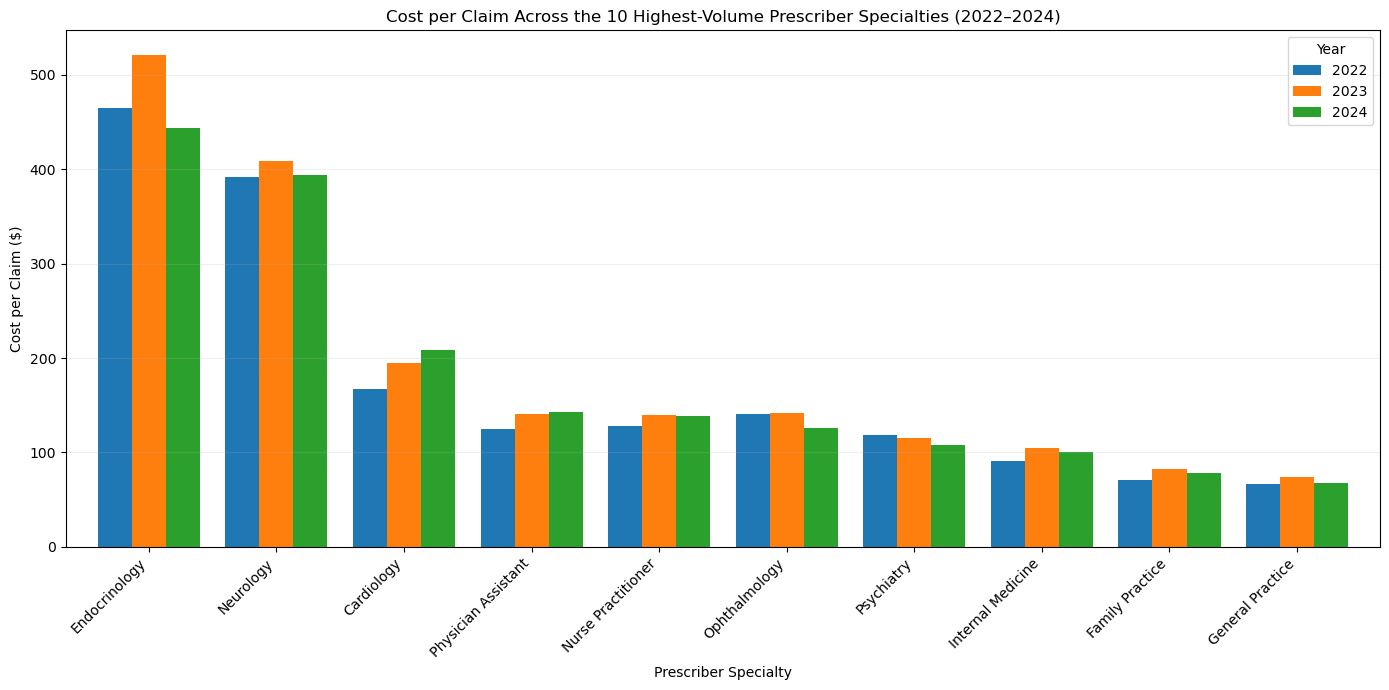

In [ ]:
import matplotlib.pyplot as plt

pivot_sorted = pivot.sort_values(by=2024, ascending=False)

ax = pivot_sorted.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title(
    "Cost per Claim Across the 10 Highest-Volume "
    "Prescriber Specialties (2022–2024)"
)
plt.xlabel("Prescriber Specialty")
plt.ylabel("Cost per Claim ($)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Year")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### Key findings:
1. Endocrinology has the highest cost per claim, reaching $521.24 in 2023 before declining to $443.42 in 2024.
2. Neurology ranks second, remaining relatively stable at approximately $392–$409 per claim.
3. Cardiology shows the strongest growth, increasing 24.8% from 2022 to 2024.
4. Family Practice and General Practice have the lowest costs among the selected specialties, below $85 per claim.
5. Most specialties experienced an increase in 2023, followed by a slight decrease in 2024.

**Cost per claim varies substantially across prescriber specialties from 2022 to 2024. Among the ten highest-volume specialties, Endocrinology and Neurology consistently have the highest costs per claim, while Family Practice and General Practice have the lowest. Notably, Cardiology's cost per claim increased by approximately 24.8% over the three-year period.**

**However, higher costs do not necessarily indicate inefficient prescribing. Differences may reflect drug types, treatment complexity, and patient needs. Further analysis comparing similar medications across specialties could help identify whether these cost differences represent potential savings opportunities.**

### Q2. How do brand-name and generic drug prescribing patterns differ in terms of cost and utilization from 2022 to 2024?

### QUESTION DESCRIPTION
Compare spending and claim volumes for brand-name and generic drugs each year. This shows whether their shares of spending differ from their shares of prescription use.

This analysis reads the clean Prescriber Summary directly and uses the official Brnd_Tot_Clms, Brnd_Tot_Drug_Cst, Gnrc_Tot_Clms and Gnrc_Tot_Drug_Cst fields. It does not require EDA SETUP. To make the two categories comparable, include prescriber-year records with all four measures observed, and report the inclusion rate. Results describe this observed cohort, not the complete national total; the prescriber mix can change by year. Missing/suppressed values are not zero-filled.

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/04 03:54:17 INFO SparkEnv: Registering MapOutputTracker
26/11/04 03:54:17 INFO SparkEnv: Registering BlockManagerMaster
26/11/04 03:54:17 INFO SparkEnv: Registering BlockManagerMasterHeartbeat
26/11/04 03:54:17 INFO SparkEnv: Registering OutputCommitCoordinator

Spark execution mode: local[1]

+----+---------------+---------------------+-------------------------+---------------------+-------------------------+
|year|prescriber_rows|Brnd_Tot_Clms_missing|Brnd_Tot_Drug_Cst_missing|Gnrc_Tot_Clms_missing|Gnrc_Tot_Drug_Cst_missing|
+----+---------------+---------------------+-------------------------+---------------------+-------------------------+
|2022|1332309        |610215               |610215                   |38492                |38492                    |
|2023|1380665        |621758               |621758                   |38406                |38406                    |
|2024|1416883        |622278               |622278                   |31303                |31303                    |
+----+---------------+---------------------+-------------------------+---------------------+-------------------------+

Complete-case coverage (interpret all results for this observed cohort):
 year  prescriber_rows  included_prescribers  included_pct
 2022          1332309                701768         52.67
 2023          1380665                737949         53.45
 2024          1416883                779916         55.04
Annual comparison (shares use brand + generic only; exclude other categories):
 year   category           spending           claims  cost_per_claim  spending_share_pct  claims_share_pct
 2022 Brand-name 148,944,057,149.82   187,412,138.00          794.74               83.28             14.60
 2022    Generic  29,895,075,894.19 1,095,999,930.00           27.28               16.72             85.40
 2023 Brand-name 177,109,270,590.92   201,279,450.00          879.92               84.81             14.95
 2023    Generic  31,731,079,329.66 1,145,423,940.00           27.70               15.19             85.05
 2024 Brand-name 201,398,781,557.79   211,858,028.00          950.63         

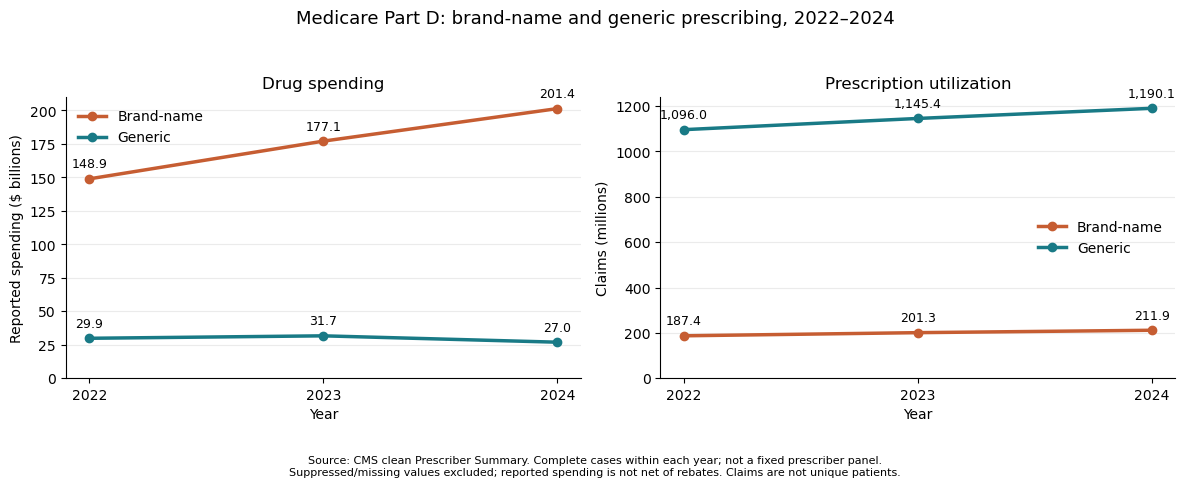

In [ ]:
from pyspark.sql import SparkSession

from pyspark.sql import functions as F
from functools import reduce
import pandas as pd
import matplotlib.pyplot as plt

q2_source = "gs://partd_data_outputs/clean/prescriber/"
q2_raw = spark.read.parquet(q2_source)
q2_metrics = ["Brnd_Tot_Clms", "Brnd_Tot_Drug_Cst",
              "Gnrc_Tot_Clms", "Gnrc_Tot_Drug_Cst"]
q2_required = ["Prscrbr_NPI", "year"] + q2_metrics
assert set(q2_required).issubset(q2_raw.columns), "Required Q2 fields are missing."
q2_base = q2_raw.select(*q2_required).filter(F.col("year").isin(2022, 2023, 2024))
for c in q2_metrics:
    q2_base = q2_base.withColumn(c, F.col(c).cast("double"))

assert q2_base.filter(F.col("Prscrbr_NPI").isNull()).limit(1).count() == 0, "Missing NPI."
assert q2_base.groupBy("Prscrbr_NPI", "year").count().filter(F.col("count") > 1).limit(1).count() == 0, "Duplicate prescriber-year keys."
q2_invalid = reduce(lambda a, b: a | b,
                    [(F.col(c) < 0) | F.isnan(c) | (F.abs(F.col(c)) == float("inf")) for c in q2_metrics])
assert q2_base.filter(q2_invalid).limit(1).count() == 0, "Invalid numeric values: inspect before analysis."

q2_audit = q2_base.groupBy("year").agg(
    F.count("*").alias("prescriber_rows"),
    *[F.sum(F.col(c).isNull().cast("long")).alias(c + "_missing") for c in q2_metrics]
).orderBy("year")
q2_audit.show(truncate=False)

q2_complete = q2_base.dropna(subset=q2_metrics)
q2_annual = q2_complete.groupBy("year").agg(
    F.count("*").alias("included_prescribers"),
    *[F.sum(c).alias(c) for c in q2_metrics]
).orderBy("year")
q2_annual_pd = q2_annual.toPandas()
q2_audit_pd = q2_audit.toPandas()
assert set(q2_annual_pd["year"].astype(int)) == {2022, 2023, 2024}, "Missing analysis year."
q2_coverage = q2_audit_pd[["year", "prescriber_rows"]].merge(
    q2_annual_pd[["year", "included_prescribers"]], on="year", validate="one_to_one")
q2_coverage["included_pct"] = 100 * q2_coverage["included_prescribers"] / q2_coverage["prescriber_rows"]
print("Complete-case coverage (interpret all results for this observed cohort):")
print(q2_coverage.to_string(index=False, float_format=lambda x: f"{x:,.2f}"))

q2_rows = []
for _, r in q2_annual_pd.iterrows():
    for category, prefix in [("Brand-name", "Brnd"), ("Generic", "Gnrc")]:
        q2_rows.append({"year": int(r["year"]), "category": category,
                        "spending": r[prefix + "_Tot_Drug_Cst"],
                        "claims": r[prefix + "_Tot_Clms"]})
q2_summary = pd.DataFrame(q2_rows).sort_values(["year", "category"])
q2_summary["cost_per_claim"] = q2_summary["spending"] / q2_summary["claims"].replace(0, float("nan"))
for metric in ["spending", "claims"]:
    denominator = q2_summary.groupby("year")[metric].transform("sum")
    q2_summary[metric + "_share_pct"] = 100 * q2_summary[metric] / denominator.replace(0, float("nan"))
print("Annual comparison (shares use brand + generic only; exclude other categories):")
print(q2_summary.to_string(index=False, float_format=lambda x: f"{x:,.2f}"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
colors = {"Brand-name": "#C65D32", "Generic": "#197A86"}
for category in ["Brand-name", "Generic"]:
    d = q2_summary[q2_summary["category"] == category].sort_values("year")
    for ax, metric, scale in [(axes[0], "spending", 1e9), (axes[1], "claims", 1e6)]:
        ax.plot(d["year"], d[metric] / scale, marker="o", linewidth=2.5,
                color=colors[category], label=category)
        for x, y in zip(d["year"], d[metric] / scale):
            ax.annotate(f"{y:,.1f}", (x, y), xytext=(0, 8),
                        textcoords="offset points", ha="center", fontsize=9)
axes[0].set(title="Drug spending", ylabel="Reported spending ($ billions)")
axes[1].set(title="Prescription utilization", ylabel="Claims (millions)")
for ax in axes:
    ax.set_xticks([2022, 2023, 2024])
    ax.set_xlabel("Year")
    ax.set_ylim(bottom=0)
    ax.margins(y=0.18)
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
fig.suptitle("Medicare Part D: brand-name and generic prescribing, 2022–2024", fontsize=13)
fig.text(0.5, 0.01, "Source: CMS clean Prescriber Summary. Complete cases within each year; not a fixed prescriber panel.\nSuppressed/missing values excluded; reported spending is not net of rebates. Claims are not unique patients.",
         ha="center", fontsize=8)
fig.tight_layout(rect=[0, 0.09, 1, 0.94])
plt.show()

### INTERPRETATION OF RESULTS

Within the analyzed cohort, brand-name drug spending increased from USD 148.9 billion in 2022 to USD 201.4 billion in 2024, while brand-name claims rose from 187.4 million to 211.9 million. Generic claims also increased, from 1,096.0 million to 1,190.1 million, but generic spending declined overall from USD 29.9 billion to USD 27.0 billion.

In 2024, generics accounted for 84.89% of combined brand-name and generic claims but only 11.81% of their spending. Brand-name drugs showed the opposite pattern: 15.11% of claims accounted for 88.19% of spending. This indicates that spending was concentrated in brand-name drugs despite their much lower prescription volume.

These findings describe prescriber records with complete brand-name and generic measures, covering approximately 53%–55% of records each year. They are not complete national totals, and changes may partly reflect differences in the prescribers and drugs included each year.

### Q3. How does drug cost per 30-day fill vary across prescribers for the same drug in the same year?

### QUESTION DESCRIPTION
Compare what a 30-day supply of the same named drug costs across prescribers within each year, to see whether costs are similar or widely spread.

Identify drugs using Brnd_Name + Gnrc_Name, and group by year and Prscrbr_NPI. Calculate total drug cost divided by total 30-day fills, using positive denominators. Drug names do not control for strength, formulation or patient mix, so differences alone do not prove waste or potential savings.

26/11/04 04:06:31 INFO SparkEnv: Registering MapOutputTracker
26/11/04 04:06:31 INFO SparkEnv: Registering BlockManagerMaster
26/11/04 04:06:31 INFO SparkEnv: Registering BlockManagerMasterHeartbeat
26/11/04 04:06:31 INFO SparkEnv: Registering OutputCommitCoordinator

Execution mode: local[1]

26/11/04 04:06:32 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.

Eligibility audit: positive finite cost/fills and nonblank keys required.
 year  source_rows  usable_rows  excluded_rows  zero_cost_rows
 2022     25869521     25867418           2103            2103
 2023     26794878     26792355           2523            2523
 2024     28023892     27995309          28583           28583
Computing distributions for ALL drugs; this is the main Spark aggregation.

Drug-year groups: 9438
Repeated rows consolidated: 0
Displayed drugs cover 23.59% of all eligible 30-day fills (2022–2024).
           Brnd_Name            Gnrc_Name  year  n_prescribers  minimum   q1  median    q3  maximum  q3_q1_ratio
 Amlodipine Besylate  Amlodipine Besylate  2022         323301     0.00 2.41    3.07  3.95    72.28         1.64
 Amlodipine Besylate  Amlodipine Besylate  2023         332507     0.04 2.65    3.45  4.54    56.84         1.71
 Amlodipine Besylate  Amlodipine Besylate  2024         343026     0.01 1.80    2.36  3.19    66.57         1.77
Atorvastatin Calcium Atorvastatin Calcium  2022         349650     0.00 4.30    5.19  6.48   131.06         1.51
Atorvastatin Calcium Atorvastatin Calcium  2023         360558     0.04 4.72    5.82  7.45   143.61         1.58
Atorvastatin Calcium Atorvastatin Calcium  2024         372319     0.00 2.91    3.73  4.96   138.89         1.71
Levothyroxine Sodium Levothyroxine Sodium  2022         267859     0.02 6.52    7.58 

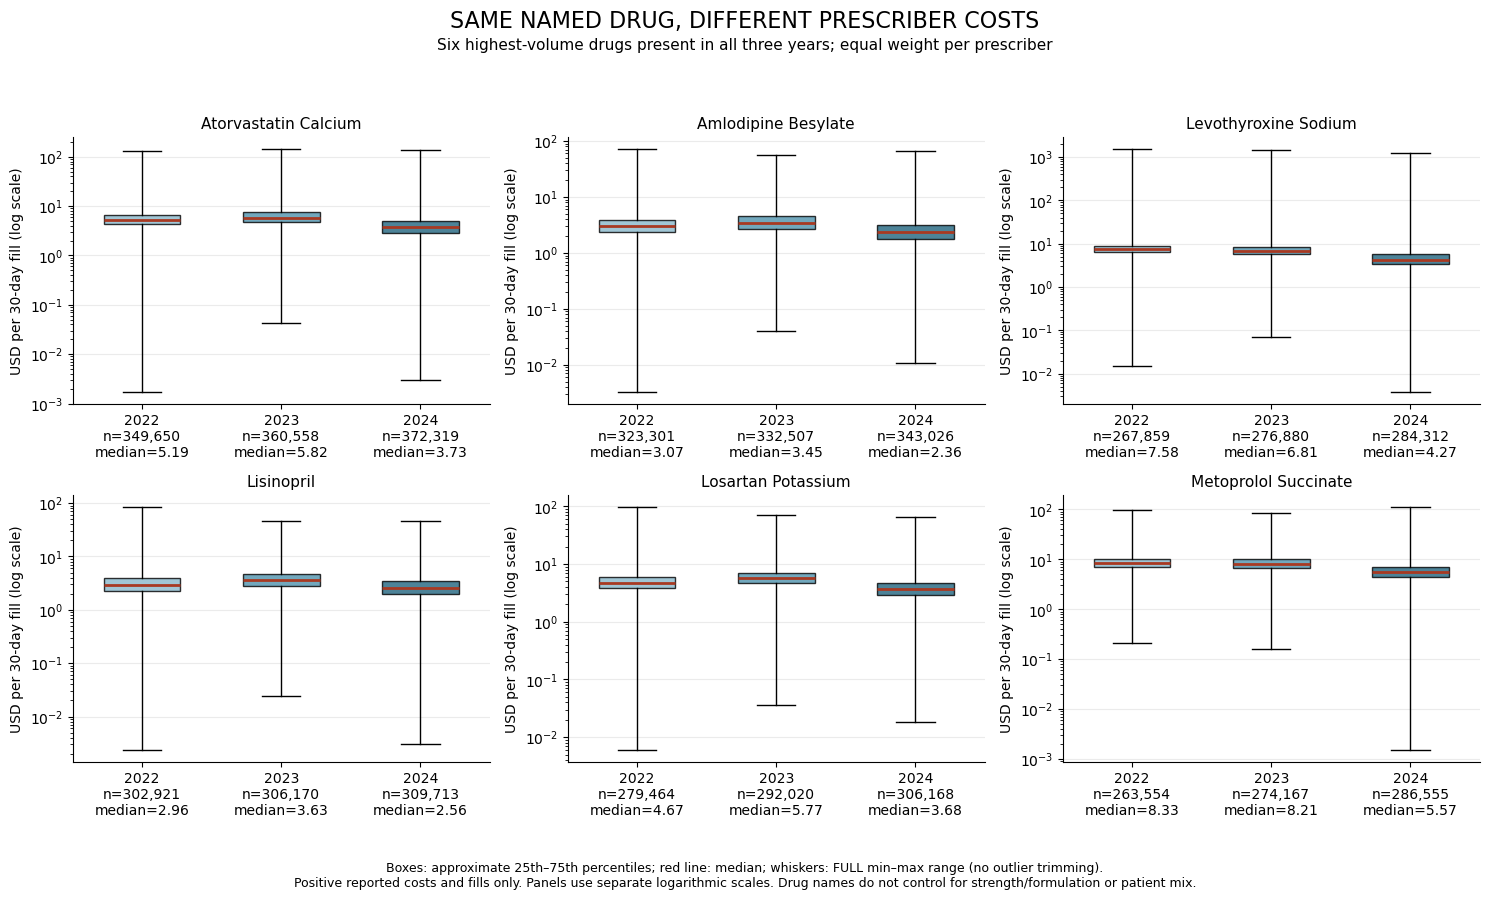

In [ ]:
from pyspark.sql import SparkSession, functions as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import textwrap

spark.sparkContext.setLogLevel("ERROR")
q3_source = "gs://partd_data_outputs/master/master_dataset/"
q3_raw = spark.read.parquet(q3_source)
q3_required = ["year", "Prscrbr_NPI", "Brnd_Name", "Gnrc_Name", "Tot_Drug_Cst", "Tot_30day_Fills"]
assert set(q3_required).issubset(q3_raw.columns), "Missing Q3 fields."
q3_base = q3_raw.select(*q3_required).filter(F.col("year").isin(2022, 2023, 2024))
for c in ["Tot_Drug_Cst", "Tot_30day_Fills"]:
    q3_base = q3_base.withColumn(c, F.col(c).cast("double"))
q3_keys_ok = F.lit(True)
for c in ["Prscrbr_NPI", "Brnd_Name", "Gnrc_Name"]:
    q3_keys_ok = q3_keys_ok & F.col(c).isNotNull() & (F.length(F.trim(F.col(c))) > 0)
q3_values_ok = F.lit(True)
for c in ["Tot_Drug_Cst", "Tot_30day_Fills"]:
    q3_values_ok = q3_values_ok & F.col(c).isNotNull() & ~F.isnan(c) & (F.abs(F.col(c)) != float("inf")) & (F.col(c) > 0)
q3_usable = F.coalesce(q3_keys_ok & q3_values_ok, F.lit(False))
q3_audit_pd = q3_base.groupBy("year").agg(
    F.count("*").alias("source_rows"),
    F.sum(q3_usable.cast("long")).alias("usable_rows"),
    F.sum((~q3_usable).cast("long")).alias("excluded_rows"),
    F.sum((F.col("Tot_Drug_Cst") == 0).cast("long")).alias("zero_cost_rows")
).orderBy("year").toPandas()
print("Eligibility audit: positive finite cost/fills and nonblank keys required.")
print(q3_audit_pd.to_string(index=False))
assert set(q3_audit_pd["year"].astype(int)) == {2022, 2023, 2024}

q3_provider = (q3_base.filter(q3_usable)
    .groupBy("Brnd_Name", "Gnrc_Name", "year", "Prscrbr_NPI")
    .agg(F.sum("Tot_Drug_Cst").alias("cost"),
         F.sum("Tot_30day_Fills").alias("fills"), F.count("*").alias("source_records"))
    .withColumn("cost_per_30day", F.col("cost") / F.col("fills")))
q3_stats = q3_provider.groupBy("Brnd_Name", "Gnrc_Name", "year").agg(
    F.count("*").alias("n_prescribers"),
    F.sum("source_records").alias("source_records"),
    F.sum("fills").alias("total_30day_fills"),
    F.sum("cost").alias("total_cost"),
    F.min("cost_per_30day").alias("minimum"),
    F.max("cost_per_30day").alias("maximum"),
    F.percentile_approx("cost_per_30day", [0.25, 0.50, 0.75], 10000).alias("quartiles"))
print("Computing distributions for ALL drugs; this is the main Spark aggregation.")
q3_stats_pd = q3_stats.toPandas()
q3_stats_pd[["q1", "median", "q3"]] = pd.DataFrame(q3_stats_pd.pop("quartiles").tolist(), index=q3_stats_pd.index)
q3_stats_pd["iqr"] = q3_stats_pd["q3"] - q3_stats_pd["q1"]
q3_stats_pd["q3_q1_ratio"] = q3_stats_pd["q3"] / q3_stats_pd["q1"]
q3_stats_pd["weighted_cost_per_30day"] = q3_stats_pd["total_cost"] / q3_stats_pd["total_30day_fills"]
q3_stats_pd = q3_stats_pd.sort_values(["Brnd_Name", "Gnrc_Name", "year"])
print("Drug-year groups:", len(q3_stats_pd))
print("Repeated rows consolidated:", int((q3_stats_pd["source_records"] - q3_stats_pd["n_prescribers"]).sum()))

q3_rank = q3_stats_pd.groupby(["Brnd_Name", "Gnrc_Name"], as_index=False).agg(
    years=("year", "nunique"), min_prescribers=("n_prescribers", "min"),
    total_fills=("total_30day_fills", "sum"))
q3_top = (q3_rank.query("years == 3 and min_prescribers >= 2")
          .sort_values(["total_fills", "Brnd_Name", "Gnrc_Name"], ascending=[False, True, True]).head(6))
assert len(q3_top) == 6, "Fewer than six eligible drugs; inspect selection."
q3_plot = q3_stats_pd.merge(q3_top[["Brnd_Name", "Gnrc_Name"]], on=["Brnd_Name", "Gnrc_Name"], validate="many_to_one")
q3_coverage = 100 * q3_plot["total_30day_fills"].sum() / q3_stats_pd["total_30day_fills"].sum()
print(f"Displayed drugs cover {q3_coverage:.2f}% of all eligible 30-day fills (2022–2024).")
print(q3_plot[["Brnd_Name", "Gnrc_Name", "year", "n_prescribers", "minimum", "q1", "median", "q3", "maximum", "q3_q1_ratio"]].to_string(index=False, float_format=lambda x: f"{x:,.2f}"))

fig3, axes3 = plt.subplots(2, 3, figsize=(15, 9))
q3_colors = ["#8AB8CB", "#4F92AD", "#21647E"]
for ax, drug in zip(axes3.flat, q3_top.itertuples(index=False)):
    d = q3_plot[(q3_plot["Brnd_Name"] == drug.Brnd_Name) & (q3_plot["Gnrc_Name"] == drug.Gnrc_Name)].sort_values("year")
    boxes = [{"label": str(int(r.year)), "whislo": r.minimum, "q1": r.q1,
              "med": r.median, "q3": r.q3, "whishi": r.maximum, "fliers": []}
             for r in d.itertuples(index=False)]
    artists = ax.bxp(boxes, showfliers=False, patch_artist=True, widths=0.55,
                     medianprops={"color": "#A83922", "linewidth": 2})
    for box, color in zip(artists["boxes"], q3_colors):
        box.set_facecolor(color)
        box.set_alpha(0.8)
    name = drug.Brnd_Name if drug.Brnd_Name == drug.Gnrc_Name else drug.Brnd_Name + " / " + drug.Gnrc_Name
    ax.set_title(textwrap.fill(name, 33), fontsize=11)
    ax.set_yscale("log")
    ax.set_ylabel("USD per 30-day fill (log scale)")
    ax.grid(axis="y", which="major", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    labels = [f"{int(r.year)}\nn={int(r.n_prescribers):,}\nmedian={r.median:.2f}" for r in d.itertuples(index=False)]
    ax.set_xticks([1, 2, 3], labels)
fig3.suptitle("SAME NAMED DRUG, DIFFERENT PRESCRIBER COSTS", fontsize=16, y=0.99)
fig3.text(0.5, 0.945, "Six highest-volume drugs present in all three years; equal weight per prescriber", ha="center", fontsize=11)
fig3.text(0.5, 0.015,
    "Boxes: approximate 25th–75th percentiles; red line: median; whiskers: FULL min–max range (no outlier trimming).\n"
    "Positive reported costs and fills only. Panels use separate logarithmic scales. Drug names do not control for strength/formulation or patient mix.",
    ha="center", fontsize=9)
fig3.tight_layout(rect=[0, 0.075, 1, 0.93])
q3_output = Path("Kefei_EDA_outputs")
q3_output.mkdir(exist_ok=True)
q3_stats_pd.to_csv(q3_output / "q3_all_drug_year_distributions.csv", index=False)
q3_audit_pd.to_csv(q3_output / "q3_eligibility_audit.csv", index=False)
q3_plot.to_csv(q3_output / "q3_plotted_drug_years.csv", index=False)
fig3.savefig(q3_output / "q3_prescriber_cost_distributions.png", dpi=180, bbox_inches="tight")
plt.show()

### INTERPRETATION OF RESULTS

Costs per 30-day fill were relatively concentrated among most prescribers for the six highest-volume drugs shown. In 2024, the 75th-percentile cost was approximately 1.60–1.77 times the 25th-percentile cost. For atorvastatin calcium, the middle 50% of prescribers had costs between USD 2.91 and USD 4.96, with a median of USD 3.73.

All six drugs had lower median costs in 2024 than in 2023, showing a consistent decline in typical costs across these commonly prescribed medications. For example, the median cost for atorvastatin calcium decreased from USD 5.82 to USD 3.73, while amlodipine besylate decreased from USD 3.45 to USD 2.36.

Extreme high-cost records stood out from the main distribution. For levothyroxine sodium in 2024, the maximum cost reached approximately USD 1,271.30, compared with a median of USD 4.27. Together, these findings highlight a pattern of relatively concentrated typical costs, declining medians in 2024, and a small number of unusually high-cost records that merit closer examination.

### Q4. How do opioid prescribing rates differ between rural and urban prescribers across specialties in 2024?

We examine how opioid prescribing rates vary between rural and urban prescribers across selected specialties in counties matched to current Primary Care Health Professional Shortage Area (HPSA) designations in 2024. This helps identify whether geographic differences in opioid prescribing patterns vary by prescriber specialty.

**Measures (prescriber-year level, CMS Prescribers by Provider):**

- Opioid prescribing rate = `Opioid_Tot_Clms / Tot_Clms × 100`
- Rural/urban classification = `Prscrbr_RUCA` (urban: major codes 1–3; rural: 4–10)
- Prescriber specialty = `Prscrbr_Type` (Family Practice, Internal Medicine, Nurse Practitioner, Physician Assistant)
- HPSA designation = current HRSA Primary Care HPSA records, linked to prescriber counties using the HUD ZIP-to-County crosswalk
- Group rates use summed opioid claims divided by summed total claims, rather than averaging individual prescriber rates.

**Data note:** HRSA data represent a current snapshot (2026 extract), not historical HPSA designations for 2024. County-level matching does not guarantee that every prescriber practices within a designated shortage area.


In [ ]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

p = spark.read.parquet(
    "gs://partd_data_outputs/clean/prescriber/"
)

hud = spark.read.parquet(
    "gs://partd_data_outputs/clean/hud_zip_county/"
)

hrsa = spark.read.parquet(
    "gs://partd_data_outputs/clean/hrsa/"
)

p.select(
    "year", "Prscrbr_NPI", "Prscrbr_RUCA",
    "Prscrbr_RUCA_Desc", "zip5_clean",
    "Tot_Clms", "Opioid_Tot_Clms"
).printSchema()

p.groupBy(
    "Prscrbr_RUCA", "Prscrbr_RUCA_Desc"
).count().orderBy(F.desc("count")).show(
    25, truncate=False
)

root
 |-- year: integer (nullable = true)
 |-- Prscrbr_NPI: string (nullable = true)
 |-- Prscrbr_RUCA: string (nullable = true)
 |-- Prscrbr_RUCA_Desc: string (nullable = true)
 |-- zip5_clean: string (nullable = true)
 |-- Tot_Clms: string (nullable = true)
 |-- Opioid_Tot_Clms: string (nullable = true)

+------------+----------------------------------------------------------------------------------------------------+-------+
|Prscrbr_RUCA|Prscrbr_RUCA_Desc                                                                                   |count  |
+------------+----------------------------------------------------------------------------------------------------+-------+
|1           |Metropolitan area core: primary flow within an urbanized area of 50,000 and greater                 |3507567|
|4           |Micropolitan area core: primary flow within an urban cluster of 10,000 to 49,999                    |244705 |
|2           |Metropolitan area high commuting: primary flow 30% or more to a urbanized area of 50,000 and greater|108447 |
|7           |Small town core: primary flow within an urban cluster of 2,500 to 9,999                             |98912  |
|1.1         |Secondary flow 30% to <50% to a larger urbanized area of 50,000 and greater                         |55266  |
|10     

In [ ]:
zip_window = Window.partitionBy("zip").orderBy(
    F.col("res_ratio").desc_nulls_last(),
    F.col("tot_ratio").desc_nulls_last(),
    F.col("geoid").asc()
)

hud_primary = (
    hud
    .withColumn(
        "row_num",
        F.row_number().over(zip_window)
    )
    .filter(F.col("row_num") == 1)
    .select(
        "zip",
        F.col("geoid").alias("county_fips")
    )
)

print("Total primary ZIP mappings:", hud_primary.count())

print(
    "Duplicate ZIPs:",
    hud_primary.groupBy("zip")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

hud_primary.show(5, truncate=False)

Total primary ZIP mappings: 39490

Duplicate ZIPs: 0

+-----+-----------+
|zip  |county_fips|
+-----+-----------+
|00501|36103      |
|00601|72001      |
|00602|72003      |
|00603|72005      |
|00604|72005      |
+-----+-----------+
only showing top 5 rows

In [ ]:
hrsa_primary = (
    hrsa
    .filter(
        F.lower(F.trim(F.col("hpsa_status")))
        == "designated"
    )
    .filter(
        F.lower(F.trim(F.col("hpsa_discipline_class")))
        == "primary care"
    )
    .filter(
        F.col("common_state_county_fips_code").isNotNull()
    )
)

hrsa_primary = hrsa_primary.withColumn(
    "county_fips",
    F.lpad(
        F.col("common_state_county_fips_code").cast("string"),
        5,
        "0"
    )
)

hrsa_county = (
    hrsa_primary
    .groupBy("county_fips")
    .agg(
        F.countDistinct("hpsa_id").alias("hpsa_count"),
        F.max("hpsa_score").alias("max_hpsa_score"),
        F.avg("hpsa_score").alias("avg_hpsa_score")
    )
)

print("Matched HPSA counties:", hrsa_county.count())

print(
    "Duplicate counties:",
    hrsa_county.groupBy("county_fips")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

hrsa_county.show(5, truncate=False)

Matched HPSA counties: 2959

Duplicate counties: 0

+-----------+----------+--------------+------------------+
|county_fips|hpsa_count|max_hpsa_score|avg_hpsa_score    |
+-----------+----------+--------------+------------------+
|36067      |4         |20.0          |16.129032258064516|
|51063      |2         |14.0          |12.0              |
|05107      |1         |14.0          |14.0              |
|31067      |2         |9.0           |8.0               |
|40079      |3         |18.0          |17.333333333333332|
+-----------+----------+--------------+------------------+
only showing top 5 rows

In [ ]:
q4 = (
    p
    .filter(F.col("year").isin(2022, 2023, 2024))
    .select(
        "Prscrbr_NPI",
        "year",
        "zip5_clean",
        "Prscrbr_RUCA",
        "Prscrbr_RUCA_Desc",
        F.col("Tot_Clms").cast("double").alias("total_claims"),
        F.col("Opioid_Tot_Clms").cast("double").alias("opioid_claims")
    )
)

q4 = q4.withColumn(
    "ruca_major",
    F.regexp_extract(
        F.trim(F.col("Prscrbr_RUCA").cast("string")),
        r"^([0-9]+)",
        1
    ).cast("int")
)

q4 = q4.withColumn(
    "area",
    F.when(F.col("ruca_major").between(1, 3), "Urban")
     .when(F.col("ruca_major").between(4, 10), "Rural")
     .when(
         F.lower(F.trim(F.col("Prscrbr_RUCA"))) == "urban",
         "Urban"
     )
     .when(
         F.lower(F.trim(F.col("Prscrbr_RUCA"))) == "rural",
         "Rural"
     )
)

q4 = (
    q4
    .join(
        hud_primary,
        q4["zip5_clean"] == hud_primary["zip"],
        "left"
    )
    .drop("zip")
)

q4 = q4.join(
    hrsa_county,
    on="county_fips",
    how="left"
)

q4.groupBy("area").agg(
    F.count("*").alias("prescriber_years"),
    F.sum(F.col("county_fips").isNull().cast("long"))
        .alias("missing_county"),
    F.sum(F.col("hpsa_count").isNull().cast("long"))
        .alias("no_hpsa_match"),
    F.sum(F.col("opioid_claims").isNull().cast("long"))
        .alias("missing_opioid_claims")
).show(truncate=False)

+-----+----------------+--------------+-------------+---------------------+
|area |prescriber_years|missing_county|no_hpsa_match|missing_opioid_claims|
+-----+----------------+--------------+-------------+---------------------+
|Urban|3678907         |196           |217810       |942129               |
|NULL |8672            |4032          |4032         |2514                 |
|Rural|442278          |6             |31826        |98323                |
+-----+----------------+--------------+-------------+---------------------+

In [ ]:
q4_valid = q4.filter(
    F.col("area").isin("Urban", "Rural")
    & F.col("hpsa_count").isNotNull()
    & F.col("opioid_claims").isNotNull()
    & (F.col("total_claims") > 0)
    & (F.col("opioid_claims") >= 0)
    & (F.col("opioid_claims") <= F.col("total_claims"))
)

total = q4.count()
kept = q4_valid.count()

print(f"Prescriber-years before filtering: {total:,}")
print(f"Prescriber-years after filtering: {kept:,}")

if total > 0:
    print(f"Retention rate: {kept / total:.1%}")

q4_valid.groupBy("year", "area").agg(
    F.count("*").alias("prescriber_years"),
    F.countDistinct("Prscrbr_NPI").alias("unique_prescribers")
).orderBy("year", "area").show()

duplicates = (
    q4_valid
    .groupBy("Prscrbr_NPI", "year")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

print("Duplicate prescriber-year keys:", duplicates)
assert duplicates == 0, "Duplicate prescriber-year records detected"

group_count = q4_valid.select(
    "year", "area"
).distinct().count()

assert group_count == 6, (
    "Expected Urban and Rural groups for all three years. "
    "Check RUCA classification and HPSA matching."
)

Prescriber-years before filtering: 4,129,857
Prescriber-years after filtering: 2,893,793
Retention rate: 70.1%

+----+-----+----------------+------------------+
|year| area|prescriber_years|unique_prescribers|
+----+-----+----------------+------------------+
|2022|Rural|          101152|            101152|
|2022|Urban|          823793|            823793|
|2023|Rural|          108168|            108168|
|2023|Urban|          860685|            860685|
|2024|Rural|          109972|            109972|
|2024|Urban|          890023|            890023|
+----+-----+----------------+------------------+

Duplicate prescriber-year keys: 0

In [ ]:
q4_summary = (
    q4_valid
    .groupBy("year", "area")
    .agg(
        F.count("*").alias("prescriber_years"),
        F.sum("opioid_claims").alias("opioid_claims"),
        F.sum("total_claims").alias("total_claims")
    )
    .withColumn(
        "opioid_rate_pct",
        F.round(
            F.col("opioid_claims")
            / F.col("total_claims") * 100,
            2
        )
    )
    .orderBy("year", "area")
)

q4_summary.show(truncate=False)

pdf = q4_summary.toPandas()

rate_table = pdf.pivot(
    index="year",
    columns="area",
    values="opioid_rate_pct"
)

rate_table["Rural - Urban (pp)"] = (
    rate_table["Rural"] - rate_table["Urban"]
).round(2)

display(rate_table.round(2))

+----+-----+----------------+-------------+-------------+---------------+
|year|area |prescriber_years|opioid_claims|total_claims |opioid_rate_pct|
+----+-----+----------------+-------------+-------------+---------------+
|2022|Rural|101152          |9500914.0    |2.23616926E8 |4.25           |
|2022|Urban|823793          |4.5736436E7  |1.03794791E9 |4.41           |
|2023|Rural|108168          |9639207.0    |2.38967499E8 |4.03           |
|2023|Urban|860685          |4.5075584E7  |1.080033905E9|4.17           |
|2024|Rural|109972          |9740993.0    |2.49431452E8 |3.91           |
|2024|Urban|890023          |4.581967E7   |1.143779155E9|4.01           |
+----+-----+----------------+-------------+-------------+---------------+

area,Rural,Urban,Rural - Urban (pp)
year,,,
2022,4.25,4.41,-0.16
2023,4.03,4.17,-0.14
2024,3.91,4.01,-0.10


**Overall result (summary table above):** Answer: Urban prescribers had slightly higher opioid prescribing rates than rural prescribers across all three years. In 2024, the rate was 4.01% for urban prescribers versus 3.91% for rural prescribers. Both groups showed declining rates from 2022 to 2024, while the rural–urban gap narrowed from 0.16 to 0.10 percentage points.

Caveat: HPSA designations come from a current snapshot rather than historical 2022–2024 data. County-level matching does not guarantee that every prescriber practices within a designated shortage area, and missing or suppressed opioid claims were excluded.

So what: The relatively small and narrowing gap suggests that rural–urban location alone may not explain much of the variation in opioid prescribing rates. Further analysis of provider specialties and patient characteristics could help explain these patterns.

In [ ]:
from pyspark.sql import functions as F

specs = [
    "Family Practice",
    "Internal Medicine",
    "Nurse Practitioner",
    "Physician Assistant"
]

specialty_lookup = (
    p.select("Prscrbr_NPI", "year", "Prscrbr_Type")
)

duplicate_keys = (
    specialty_lookup
    .groupBy("Prscrbr_NPI", "year")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

assert duplicate_keys == 0, "Check duplicate specialty records"

q4_specialty = q4_valid.join(
    specialty_lookup,
    on=["Prscrbr_NPI", "year"],
    how="left"
)

specialty_summary = (
    q4_specialty
    .filter(F.col("year") == 2024)
    .filter(F.col("Prscrbr_Type").isin(specs))
    .groupBy("Prscrbr_Type", "area")
    .agg(
        F.count("*").alias("prescribers"),
        F.sum("opioid_claims").alias("opioid_claims"),
        F.sum("total_claims").alias("total_claims")
    )
    .withColumn(
        "opioid_rate_pct",
        F.round(
            F.col("opioid_claims")
            / F.col("total_claims") * 100,
            2
        )
    )
    .orderBy("Prscrbr_Type", "area")
)

specialty_summary.show(truncate=False)

+-------------------+-----+-----------+-------------+------------+---------------+
|Prscrbr_Type       |area |prescribers|opioid_claims|total_claims|opioid_rate_pct|
+-------------------+-----+-----------+-------------+------------+---------------+
|Family Practice    |Rural|16133      |3255341.0    |9.1195213E7 |3.57           |
|Family Practice    |Urban|71148      |7504217.0    |2.71974016E8|2.76           |
|Internal Medicine  |Rural|6877       |1248243.0    |3.8903854E7 |3.21           |
|Internal Medicine  |Urban|86280      |6558492.0    |2.8254196E8 |2.32           |
|Nurse Practitioner |Rural|32484      |2370615.0    |6.744252E7  |3.52           |
|Nurse Practitioner |Urban|174202     |8207531.0    |1.97417795E8|4.16           |
|Physician Assistant|Rural|11090      |952897.0     |2.0913888E7 |4.56           |
|Physician Assistant|Urban|84442      |5383250.0    |7.2567216E7 |7.42           |
+-------------------+-----+-----------+-------------+------------+---------------+

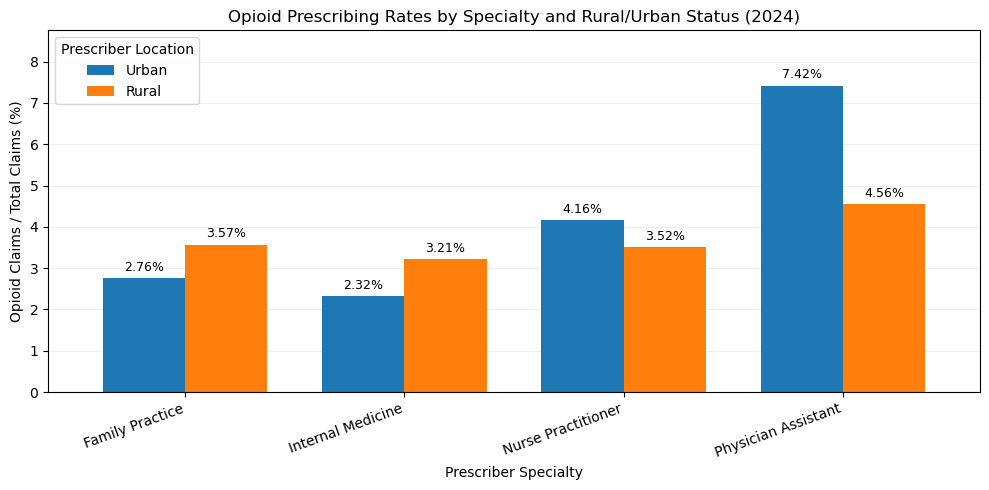

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

spec_pdf = specialty_summary.toPandas()

spec_plot = spec_pdf.pivot(
    index="Prscrbr_Type",
    columns="area",
    values="opioid_rate_pct"
).reindex(specs)

assert spec_plot[["Urban", "Rural"]].notna().all().all(), (
    "Missing Urban/Rural rates for some specialties"
)

ax = spec_plot[["Urban", "Rural"]].plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title(
    "Opioid Prescribing Rates by Specialty and Rural/Urban Status (2024)"
)
ax.set_xlabel("Prescriber Specialty")
ax.set_ylabel("Opioid Claims / Total Claims (%)")
ax.set_xticklabels(specs, rotation=20, ha="right")
ax.legend(title="Prescriber Location")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3,
        fontsize=9
    )

ax.set_ylim(0, spec_plot.max().max() * 1.18)

plt.tight_layout()
plt.show()

Answer: Opioid prescribing rates varied by specialty and rural/urban location in 2024. Rural rates were higher in Family Practice (3.57% vs. 2.76%) and Internal Medicine (3.21% vs. 2.32%), while urban rates were higher among Nurse Practitioners (4.16% vs. 3.52%) and Physician Assistants (7.42% vs. 4.56%). The largest difference was among Physician Assistants, with urban rates 2.86 percentage points higher.

Caveat: These differences may reflect variations in patient needs and practice settings. HPSA designations come from a current snapshot, county-level matching does not confirm that every prescriber is within a designated shortage area, and records with missing or suppressed opioid claims were excluded.

So what: The direction and size of rural–urban differences vary across specialties, suggesting that geographic comparisons should also consider provider specialty rather than relying on overall averages alone.

### Q5. Do prescribers serving more low-income (dual-eligible) patients prescribe generics at a different rate?

Dual-eligible patients qualify for both Medicare and Medicaid, so this tells us whether low-income patients get more or fewer generics. That matters for both cost and access.

**Measures (prescriber-year level, Prescribers by Provider table):**
- Dual-eligible share = `Bene_Dual_Cnt / (Bene_Dual_Cnt + Bene_Ndual_Cnt)`
- Generic rate = `Gnrc_Tot_Clms / (Brnd_Tot_Clms + Gnrc_Tot_Clms)`
- Group rates use summed claims divided by summed claims, per the team's cost rule.

In [ ]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

p = spark.read.parquet("gs://partd_data_outputs/clean/prescriber")

cols = ["year", "Prscrbr_NPI", "Prscrbr_Type", "Brnd_Tot_Clms", "Gnrc_Tot_Clms",
        "Bene_Dual_Cnt", "Bene_Ndual_Cnt"]
p.select(cols).printSchema()

root
 |-- year: integer (nullable = true)
 |-- Prscrbr_NPI: string (nullable = true)
 |-- Prscrbr_Type: string (nullable = true)
 |-- Brnd_Tot_Clms: string (nullable = true)
 |-- Gnrc_Tot_Clms: string (nullable = true)
 |-- Bene_Dual_Cnt: string (nullable = true)
 |-- Bene_Ndual_Cnt: string (nullable = true)

In [ ]:
q5 = (p
    .withColumn("bg_clms", F.col("Brnd_Tot_Clms") + F.col("Gnrc_Tot_Clms"))
    .withColumn("dual_share", F.col("Bene_Dual_Cnt") / (F.col("Bene_Dual_Cnt") + F.col("Bene_Ndual_Cnt")))
    .withColumn("generic_rate", F.col("Gnrc_Tot_Clms") / F.col("bg_clms"))
    .filter(F.col("dual_share").isNotNull() & F.col("generic_rate").isNotNull() & (F.col("bg_clms") >= 50))
)

total, kept = p.count(), q5.count()
print(f"Prescriber-years kept: {kept:,} of {total:,} ({kept/total:.1%}); "
      "the rest have suppressed counts or fewer than 50 brand/generic claims")

q5.groupBy("year").agg(
    F.count("*").alias("prescribers"),
    F.round(F.corr("dual_share", "generic_rate"), 3).alias("correlation")
).orderBy("year").show()

Prescriber-years kept: 1,427,153 of 4,129,857 (34.6%); the rest have suppressed counts or fewer than 50 brand/generic claims

+----+-----------+-----------+
|year|prescribers|correlation|
+----+-----------+-----------+
|2022|     448163|     -0.011|
|2023|     474860|      0.035|
|2024|     504130|      0.033|
+----+-----------+-----------+

In [ ]:
binned = (q5
    .withColumn("dual_band", F.least(F.floor(F.col("dual_share") * 10), F.lit(9)))
    .groupBy("year", "dual_band")
    .agg(F.count("*").alias("prescribers"),
         (F.sum("Gnrc_Tot_Clms") / F.sum("bg_clms")).alias("generic_rate"))
    .orderBy("year", "dual_band"))

pdf = binned.toPandas()
pdf["band"] = (pdf["dual_band"] * 10).astype(int).astype(str) + "-" + (pdf["dual_band"] * 10 + 10).astype(int).astype(str) + "%"
pdf["generic_pct"] = (pdf["generic_rate"] * 100).round(1)
pdf.pivot(index="band", columns="year", values="generic_pct")

year,2022,2023,2024
band,,,
0-10%,86.9,85.9,86.3
10-20%,85.7,85.0,84.6
20-30%,84.9,84.8,84.1
30-40%,84.7,84.7,84.3
40-50%,85.3,85.2,84.9
50-60%,85.3,85.3,85.3
60-70%,84.9,85.1,85.3
70-80%,84.4,84.7,85.0
80-90%,84.1,84.6,84.8


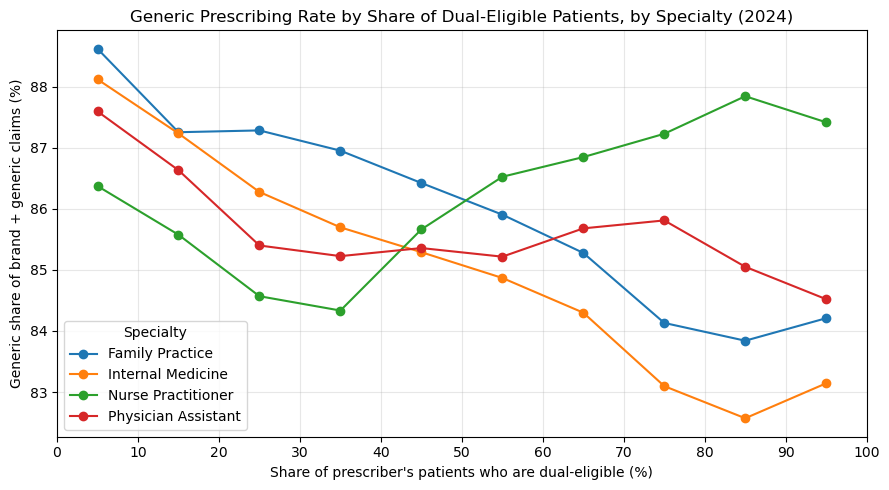

In [ ]:
specs = ["Family Practice", "Internal Medicine", "Nurse Practitioner", "Physician Assistant"]

spec_pdf = (q5
    .filter((F.col("year") == 2024) & F.col("Prscrbr_Type").isin(specs))
    .withColumn("dual_band", F.least(F.floor(F.col("dual_share") * 10), F.lit(9)))
    .groupBy("Prscrbr_Type", "dual_band")
    .agg(F.count("*").alias("prescribers"),
         (F.sum("Gnrc_Tot_Clms") / F.sum("bg_clms")).alias("generic_rate"))
    .filter(F.col("prescribers") >= 30)
    .orderBy("Prscrbr_Type", "dual_band")
    .toPandas())

fig, ax = plt.subplots(figsize=(9, 5))
for spec in specs:
    g = spec_pdf[spec_pdf["Prscrbr_Type"] == spec]
    ax.plot(g["dual_band"] * 10 + 5, g["generic_rate"] * 100, marker="o", label=spec)

ax.set_title("Generic Prescribing Rate by Share of Dual-Eligible Patients, by Specialty (2024)")
ax.set_xlabel("Share of prescriber's patients who are dual-eligible (%)")
ax.set_ylabel("Generic share of brand + generic claims (%)")
ax.set_xticks(range(0, 101, 10))
ax.legend(title="Specialty")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
top5 = [r["Prscrbr_Type"] for r in
        q5.groupBy("Prscrbr_Type").count().orderBy(F.desc("count")).limit(5).collect()]

(q5.filter(F.col("Prscrbr_Type").isin(top5))
   .groupBy("Prscrbr_Type")
   .agg(F.count("*").alias("prescribers"),
        F.round(F.corr("dual_share", "generic_rate"), 3).alias("correlation"))
   .orderBy(F.desc("prescribers"))
   .show(truncate=False))

+-------------------+-----------+-----------+
|Prscrbr_Type       |prescribers|correlation|
+-------------------+-----------+-----------+
|Nurse Practitioner |305355     |0.03       |
|Family Practice    |200895     |-0.32      |
|Internal Medicine  |176406     |-0.21      |
|Physician Assistant|137337     |-0.098     |
|Ophthalmology      |42572      |-0.127     |
+-------------------+-----------+-----------+

Answer: Overall, no: generic rates are 84–87% in every dual-eligible band, and the correlation is near zero (r = −0.01 to 0.04, 2022–2024). Within primary care, however, prescribers with more dual-eligible patients prescribe fewer generics (Family Practice r = −0.32, Internal Medicine r = −0.21); the flat overall trend reflects differences in specialty mix. Nurse practitioners show the opposite trend: their generic rate rises to about 87–88% among prescribers with mostly dual-eligible patients, which offsets the primary care decline in the overall numbers.

Caveat: 65% of prescriber-years were excluded because of CMS suppression (counts under 11) or fewer than 50 claims, so small practices are underrepresented. This is an association, not a cause.

So what: Primary care practices serving many low-income Medicare patients are a promising target for generic substitution efforts.

> **Takeaway (exploratory analysis):** Brand-name drugs account for most spending, and the meaningful differences in cost, generic use, and opioid prescribing appear within specialties rather than in overall or geographic averages.

## 7. Conclusions

### 1. Brand-name drugs are the primary driver of Medicare Part D spending
Brand-name drugs account for approximately 88% of reported drug spending but only 15% of claims in 2024, revealing a substantial imbalance between prescription volume and expenditure. From 2022 to 2024, brand-name spending increased from \$148.9 billion to \$201.4 billion (35.3%), while generic spending declined from \$29.9 billion to \$27.0 billion (9.7%). Meanwhile, generic claims increased from approximately 1.10 billion to 1.19 billion, indicating that generics continue to serve the majority of prescription demand at a much lower aggregate cost.

Further analysis of six high-volume drugs shows that median reported costs per 30-day fill generally decreased in 2024 compared with 2023, and costs were fairly consistent across most prescribers (the middle half within about 1.6–1.8× of each other), although some prescribers show extreme high costs. This suggests that spending-reduction efforts should investigate drug selection and opportunities for appropriate generic substitution rather than assuming that differences in prices paid across prescribers are the primary source of excess spending.

- **Recommendation:** Prioritize high-spending brand-name medications with clinically appropriate generic equivalents. Identify drugs with substantial prescribing volume and cost differences, then estimate potential savings from substitution while accounting for clinical suitability.
- **Impact / Feasibility:** High / Medium
- **Limitations:** Reported CMS spending excludes manufacturer rebates and discounts, so gross spending reductions do not necessarily translate into equivalent net savings. The same drug name may also include different strengths and formulations, limiting direct price comparisons.

### 2. Generic prescribing patterns differ by patients' socioeconomic characteristics and prescriber specialty
Among Family Practice and Internal Medicine prescribers, generic prescribing rates generally decline as the proportion of dual-eligible Medicare–Medicaid patients increases. Family Practice rates decrease from approximately 88.6% to 84.2%, while Internal Medicine rates decline from 88.1% to 83.1% across the observed dual-eligible-share groups. In contrast, Nurse Practitioners exhibit an overall upward trend at higher dual-eligible shares, demonstrating that the relationship is not consistent across specialties.

These findings suggest that socioeconomic patient composition is associated with prescribing patterns, but specialty-specific differences are important. Rather than implementing uniform generic-prescribing initiatives, targeted interventions may be more effective.

- **Recommendation:** Pilot targeted generic-prescribing education and clinical decision-support initiatives among Family Practice and Internal Medicine prescribers serving high proportions of dual-eligible patients. Evaluate changes in generic prescribing rates, medication spending, and clinical appropriateness before expanding the intervention.
- **Impact / Feasibility:** Medium / High
- **Limitations:** The relationships are observational and do not establish causation. Differences may reflect patient diagnoses, drug availability, treatment needs, or insurance coverage. CMS suppression and low-volume exclusions may also affect the representativeness of the findings.

### 3. Prescriber specialty and practice setting reveal important differences in prescribing costs and patterns
Cost per claim varies substantially across the ten highest-volume prescriber specialties. In 2024, Endocrinology had the highest cost per claim at approximately \$443, followed by Neurology at \$394, while Family Practice and General Practice remained below \$85. Cardiology also experienced a notable 24.8% increase in cost per claim between 2022 and 2024, reaching approximately \$209.

Geographic comparisons of opioid prescribing reveal additional differences within specialties. In 2024, rural Family Practice and Internal Medicine prescribers had higher opioid claim shares than their urban counterparts, while the opposite pattern appeared among Nurse Practitioners and Physician Assistants. The largest difference occurred among Physician Assistants, whose urban opioid claim share was 7.42%, compared with 4.56% in rural areas—a 2.86 percentage-point gap.

Together, these findings indicate that prescribing patterns cannot be adequately understood using overall averages alone. Both specialty and practice settings should be considered when interpreting cost variation and identifying unusual prescribing behavior.

- **Recommendation:** Develop specialty-specific benchmarking to compare prescribers with clinically relevant peers, incorporating geographic characteristics and patient complexity where available. Prioritize further investigation of high-cost specialties and prescribing patterns that differ substantially from comparable groups.
- **Impact / Feasibility:** Medium / High
- **Limitations:** Higher costs may reflect more complex conditions, specialized medications, or differences in patient populations rather than inefficient prescribing. Opioid claim shares also do not independently establish inappropriate prescribing, and rural–urban comparisons do not fully measure healthcare provider shortage severity.

### Limitations
This analysis has several limitations. First, the reported costs represent gross Medicare Part D spending and do not account for rebates or other price concessions. Additionally, CMS suppresses counts below 11, which may lead to underrepresentation of smaller prescribers. The analysis also relies on 2026 HRSA shortage designations and a single HUD ZIP-county crosswalk from Q4 2024 applied across all three years, potentially overlooking changes over time. It is also important to note all findings reflect observational associations rather than causal relationships.

### Overall
The findings suggest that the greatest potential for Medicare Part D cost optimization lies in appropriate medication selection and targeted prescribing interventions, rather than broad cost-reduction measures applied uniformly across prescribers. Brand-name drugs account for a disproportionate share of reported spending, while generic prescribing patterns vary across patient populations and specialties. Substantial differences in costs and opioid prescribing demonstrate the importance of evaluating prescribers within comparable clinical and geographic contexts.

### Next steps (final deliverable)
Future analyses should match brand-name drugs with therapeutically equivalent generics based on drug name, strength, and dosage form to estimate potential savings at the same prescription volume. Prescribers with unusually high costs per claim should also be identified through comparisons with peers in the same specialty and state. Additionally, further analysis should examine whether the relationship between dual-eligible patient share and generic prescribing remains after accounting for differences in drug mix. Finally, identifying the specialties and regions with the greatest potential savings would help prioritize targeted cost-reduction strategies.

## References
- Apache Software Foundation. (n.d.). *PySpark documentation*. Retrieved November 2026, from https://spark.apache.org/docs/latest/api/python/
- Centers for Medicare & Medicaid Services. (n.d.). *Medicare Part D prescribers – by provider* [Data set]. Retrieved October 2026, from https://data.cms.gov/provider-summary-by-type-of-service/medicare-part-d-prescribers/medicare-part-d-prescribers-by-provider
- Centers for Medicare & Medicaid Services. (n.d.). *Medicare Part D prescribers – by provider and drug* [Data set]. Retrieved October 2026, from https://data.cms.gov/provider-summary-by-type-of-service/medicare-part-d-prescribers/medicare-part-d-prescribers-by-provider-and-drug
- Centers for Medicare & Medicaid Services. (n.d.). *Medicare Part D prescribers methodology*. Retrieved October 2026, from https://data.cms.gov/resources/medicare-part-d-prescribers-methodology
- Centers for Medicare & Medicaid Services. (n.d.). *Medicare Part D spending by drug* [Data set]. Retrieved October 2026, from https://data.cms.gov/summary-statistics-on-use-and-payments/medicare-medicaid-spending-by-drug/medicare-part-d-spending-by-drug
- Health Resources & Services Administration. (n.d.). *Health Professional Shortage Areas (HPSA) data download* [Data set]. Retrieved October 2026, from https://data.hrsa.gov/data/download
- U.S. Department of Agriculture, Economic Research Service. (n.d.). *Rural-Urban Commuting Area codes* [Data set]. Retrieved November 2026, from https://www.ers.usda.gov/data-products/rural-urban-commuting-area-codes/
- U.S. Department of Housing and Urban Development, Office of Policy Development and Research. (n.d.). *HUD USPS ZIP code crosswalk files* [Data set]. Retrieved October 2026, from https://www.huduser.gov/portal/datasets/usps_crosswalk.html

## Generative AI Disclosure
Alexander Shah used Claude (Anthropic) to search for candidate datasets and draft wording for the project proposal, to review an earlier draft of the HRSA/HUD cleaning, to help plan the team's workflow and exploratory questions, to write and run the PySpark code and chart for Q5 (dual-eligible patients and generic prescribing), to assemble this notebook from team members' sections, and to draft the header, executive summary, conclusions, references, and this disclosure. The Q5 outputs were reviewed against the data, the chart was revised to show specialty-level results after the first version exaggerated a small overall difference, and the team reviewed and edited all drafted text.

Zexuan Wang used ChatGPT as an auxiliary tool to identify potential errors and suggest improvements to the initial drafts of the data cleaning and joining procedures. AI assistance also helped clarify logic and troubleshoot technical issues.

Kefei Zhang used ChatGPT to discuss possible visualization approaches for Q3, including which types of charts would best represent the findings. Kefei evaluated its suggestions and reviewed the final visualizations to ensure they accurately reflected the data.

Anna Wei used Claude (Anthropic) during the data loading and cleaning phase to review missing and null values, discuss standardization methodologies, and identify data quality issues in the raw files. Claude also provided guidance on how to organize and save the cleaned data as Parquet files in Google Cloud Storage so the team could easily access and work with the data.

Linh Le used ChatGPT to assist with notebook setup, debug coding errors, and review and evaluate the report against the grading rubric to identify areas for improvement and ensure alignment with project requirements.

Stephanie Chen used ChatGPT (OpenAI) during the exploratory data analysis phase to assist with PySpark coding and debugging for Q4. ChatGPT also helped refine the research question to a more detailed version. All code and results were tested and reviewed in JupyterLab to ensure accuracy.